# Proyecto Final · Caso B
## ¿Qué pedidos llegarán tarde? Predicción de retrasos en TransAndes

**Analítica de Datos I · Universidad Icesi · 2026-02**

**Integrantes:** Samuel Restrepo Giraldo · Sara sofía Perez · Manuela Giraldo Ochoa


**Codigos:** 







---
# FASE 1 · Comprensión del negocio

## 1.1 El problema, con nuestras palabras

TransAndes despacha pedidos desde cuatro centros (Cali, Bogotá, Medellín y Barranquilla) con motos, furgones y camiones, hacia zonas urbanas, periurbanas y rurales. A cada cliente le promete una ventana de entrega. En 2025, cerca de 3 de cada 10 pedidos llegaron tarde.

Un pedido tarde le cuesta a la empresa quejas, penalidades con clientes empresariales y pérdida de clientes. TransAndes se entera del retraso cuando ya ocurrió y no puede hacer nada. Lo que quiere la gerencia es saberlo en el momento del despacho, cuando todavía puede reaccionar (cambiar el vehículo o el conductor, adelantar la salida, avisarle al cliente).

Pregunta de negocio: con la información disponible al momento del despacho, ¿podemos predecir si un pedido llegará tarde? ¿Qué condiciones de la operación aumentan el riesgo?

Lo planteamos como un problema de clasificación binaria supervisada:

- La variable que queremos predecir es entrega_tardia (Sí / No).
- La clase que nos interesa detectar, la positiva, es "Sí" (llega tarde).
- Usamos la información que ya se tiene al momento del despacho: distancia, peso, número de paradas, hora de salida, clima, experiencia del conductor, edad del vehículo, tipo de cliente y prioridad del pedido.

Si el modelo avisa en el despacho, la gerencia todavía puede reaccionar. Si de verdad se puede predecir, y qué condiciones pesan más, lo respondemos con datos a lo largo del notebook: la respuesta final está en la Fase 6.

## 1.2 ¿Qué es un acierto y qué es un error?

Con "tarde" como clase positiva, cada predicción del modelo cae en una de cuatro casillas:

| | El pedido llegó TARDE (real) | El pedido llegó A TIEMPO (real) |
|---|---|---|
| Modelo dice TARDE | Verdadero positivo (acierto): alertó a tiempo y se pudo actuar |  Falso positivo (error): falsa alarma; se tomaron medidas extra para un pedido que iba bien |
| Modelo dice A TIEMPO | Falso negativo (error): el retraso nadie lo vio venir |  Verdadero negativo (acierto): no molestó a operaciones; el pedido llegó bien |

- Acierto = el modelo predice lo que realmente pasó (verdaderos positivos y verdaderos negativos).
- Error = el modelo se equivoca, y hay dos tipos de error que no cuestan lo mismo.

## 1.3 ¿Qué es más costoso: un falso negativo o un falso positivo?

Falso negativo (decir "llegará a tiempo" y llega tarde):
- El retraso ocurre sin que nadie haya podido evitarlo.
- Consecuencias: penalidades con clientes empresariales, quejas, y clientes que se van. Son costos altos y, en el caso de la pérdida de un cliente, difíciles de recuperar.

Falso positivo (decir "llegará tarde" y llega bien):
- El costo es solo el de la medida preventiva que se tomó para nada, es decir, reasignar un vehículo o un conductor con más experiencia, adelantar la salida, o avisarle al cliente.
- Es un costo pequeño y controlable, y además no daña la relación con el cliente.

Conclusión: el falso negativo es más costoso para TransAndes. Por eso la métrica que priorizamos es el recall de la clase "tarde": de todos los pedidos que realmente van a llegar tarde, ¿cuántos logramos detectar?

Pero no podemos mirar solo el recall. Un modelo que dijera "todo pedido llegará tarde" tendría recall de 100 %, pero le llenaría a operaciones el día de falsas alarmas y las medidas dejarían de ser efectivas. Por eso también vigilamos:
- Precision: de los pedidos que el modelo marca como riesgosos, ¿cuántos de verdad llegan tarde? (controla las falsas alarmas).
- F1: el balance entre precision y recall.
- No nos fiamos del accuracy: como la mayoría de pedidos llegan a tiempo, un modelo que dijera siempre "a tiempo" tendría un accuracy alto sin servir para nada (lo comprobamos con datos en la Fase 2).

| Métrica | ¿Qué responde? | Papel en el proyecto |
|---|---|---|
| Recall (clase tarde)| De los que llegan tarde, ¿cuántos detecto? | Prioritaria |
| Precision (clase tarde) | De los que marco como riesgo, ¿cuántos eran de verdad? | Control de falsas alarmas |
| F1 | Balance entre las dos | Criterio de desempate |
| Accuracy | % total de aciertos | Referencia, puede engañar |

---
# FASE 2 · Comprensión de los datos (EDA)

## 2.0 Preparación del entorno 

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata



In [2]:
MORADO  = "#5353EE"
LILA    = "#B8B8F0"
ROJO    = "#E5484D"
NARANJA = "#FF8A00"

sns.set_theme(style="whitegrid")

## 2.1 Carga y primer vistazo a los datos 
Cargamos el archivo: df es nuestra copia original. Más adelante crearemos una copia de trabajo para graficar.

In [3]:
df = pd.read_csv("logistica_entregas.csv")
print("Dimensiones (filas, columnas):", df.shape)
df.head()

Dimensiones (filas, columnas): (8035, 17)


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.9,115.5,10.0,19.0,Lluvia,5.7,9.0,Empresa,Normal,193700.0,Sí
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.7,264.3,NaN,17.0,Lluvia,3.2,4.0,NaN,Normal,361300.0,Sí
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.6,NaN,7.0,20.0,Soleado,NaN,5.0,Hogar,Express,170600.0,No
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.1,9.2,1.0,6.0,Soleado,10.2,5.0,Empresa,Normal,622400.0,No
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.2,260.5,1.0,5.0,Lluvia,6.5,15.0,Hogar,Normal,406500.0,No


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8035 entries, 0 to 8034
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_pedido                    8035 non-null   str    
 1   fecha_despacho               8035 non-null   str    
 2   dia_semana                   8035 non-null   str    
 3   centro_distribucion          8035 non-null   str    
 4   zona_destino                 8035 non-null   str    
 5   tipo_vehiculo                8035 non-null   str    
 6   distancia_km                 7633 non-null   float64
 7   peso_kg                      7391 non-null   float64
 8   num_paradas                  7550 non-null   float64
 9   hora_salida                  7713 non-null   float64
 10  clima                        7311 non-null   str    
 11  experiencia_conductor_anios  7149 non-null   float64
 12  edad_vehiculo_anios          7475 non-null   float64
 13  tipo_cliente                 

In [5]:
# Resumen estadístico de las variables numéricas
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
distancia_km,7633.0,34.21,36.32,-144.1,11.30,19.4,43.50,299.0
peso_kg,7391.0,370.06,616.10,0.0,10.45,143.3,328.05,6341.2
num_paradas,7550.0,6.56,3.44,0.0,4.00,6.0,9.00,23.0
hora_salida,7713.0,12.53,4.59,5.0,9.00,12.0,16.00,30.0
experiencia_conductor_anios,7149.0,4.98,3.49,0.1,2.40,4.2,6.60,30.0
edad_vehiculo_anios,7475.0,7.35,4.58,0.0,3.00,7.0,11.00,15.0
valor_pedido_COP,7634.0,301474.63,296305.39,11300.0,125800.00,216000.0,374875.00,5752400.0


In [6]:
# Resumen de las variables de texto (categóricas)
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
id_pedido,8035,8000,P-06259,2
fecha_despacho,8035,365,2025-12-10,39
dia_semana,8035,7,Lunes,1206
centro_distribucion,8035,10,Cali,2688
zona_destino,8035,3,Urbana,4379
tipo_vehiculo,8035,7,Furgón,3487
clima,7311,4,Soleado,2891
tipo_cliente,7792,3,Hogar,3541
prioridad,8035,2,Normal,6056
entrega_tardia,8035,2,No,5513


La base tiene 8.035 pedidos y 17 columnas, todos despachados en 2025. Cuenta con 7 variables numéricas (distancia_km, peso_kg, num_paradas, hora_salida, experiencia_conductor_anios, edad_vehiculo_anios y valor_pedido_COP) y 10 variables de texto, entre ellas la fecha, el ID y la variable objetivo. Además, nueve columnas no tienen las 8.035 filas completas, es decir, presentan valores nulos: clima, experiencia_conductor_anios, peso_kg, edad_vehiculo_anios, num_paradas, distancia_km, valor_pedido_COP, hora_salida y tipo_cliente, los cuales cuantificaremos en el siguiente paso. Por otra parte, el análisis con describe() permite identificar valores que no tienen sentido, tal como se advertía en la guía, ya que la base viene sucia intencionalmente. Por ejemplo, distancia_km presenta un mínimo de -144 km, aunque una distancia no puede ser negativa, y un máximo de 299 km. La variable hora_salida debería estar entre 0 y 23, pero alcanza un valor de 30. Asimismo, num_paradas tiene un mínimo de 0, aunque una ruta con cero entregas no debería considerarse una ruta, y peso_kg también presenta un mínimo de cero. Adicionalmente, peso_kg y valor_pedido_COP tienen valores máximos muy alejados de sus medianas, alcanzando los 6.341 kg y los $5,75 millones, respectivamente. Finalmente, en las variables categóricas se observa que centro_distribucion tiene 10 valores únicos y tipo_vehiculo tiene 7, cuando deberían tener únicamente 4 y 3 categorías, respectivamente. Esto indica que existen categorías escritas de diferentes maneras.

## 2.2 Valores nulos

,nulos,% del total
experiencia_conductor_anios,886,11.0
clima,724,9.0
peso_kg,644,8.0
edad_vehiculo_anios,560,7.0
num_paradas,485,6.0
distancia_km,402,5.0
valor_pedido_COP,401,5.0
hora_salida,322,4.0
tipo_cliente,243,3.0


Columnas con nulos: 9 de 17
Filas con al menos un nulo: 3593 de 8035 (44.7 %)


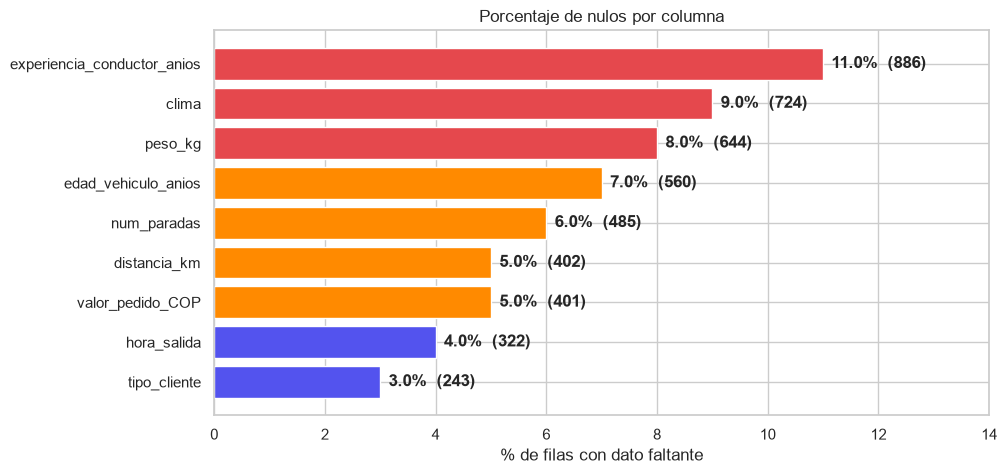

In [7]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% del total": (df.isna().mean() * 100).round(1),
})
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
display(nulos)   # en un script normal usa print(nulos)

print(f"Columnas con nulos: {len(nulos)} de {df.shape[1]}")
print(f"Filas con al menos un nulo: {df.isna().any(axis=1).sum()} de {len(df)} "
      f"({df.isna().any(axis=1).mean()*100:.1f} %)")

# Gráfica: porcentaje de nulos por columna
plt.figure(figsize=(10, 5))
orden = nulos.sort_values("% del total").index
valores = nulos.loc[orden, "% del total"]
colores = [ROJO if v >= 8 else NARANJA if v >= 5 else MORADO for v in valores]
plt.barh(orden, valores, color=colores)
for i, v in enumerate(valores):
    plt.text(v + 0.15, i, f"{v}%  ({nulos.loc[orden[i], 'nulos']})", va="center", fontweight="bold")
plt.title("Porcentaje de nulos por columna")
plt.xlabel("% de filas con dato faltante")
plt.xlim(0, valores.max() + 3)
plt.show()

### Interpretación

Las variables que no presentan valores nulos son el ID, la fecha, el día de la semana, el centro de distribución, la zona, el vehículo, la prioridad y la variable objetivo. Debido a que los valores nulos están distribuidos entre varias columnas, si elimináramos todas las filas que contienen al menos un valor faltante, perderíamos 3.593 de los 8.035 registros, lo que equivale aproximadamente al 45 % de la base de datos. Esta pérdida de información sería considerable, por lo que resulta más conveniente imputar los valores faltantes en lugar de eliminar las filas, decisión que tomamos en la Fase 3.

### ¿Los nulos esconden información sobre el retraso?
Antes de decidir cómo tratarlos, conviene preguntar: ¿los pedidos con dato faltante llegan tarde con más frecuencia?

In [8]:
df["_tarde"] = (df["entrega_tardia"] == "Sí").astype(int)
filas = []
for c in nulos.index:
    filas.append({"columna": c,
                  "% tarde si el dato falta": df.loc[df[c].isna(), "_tarde"].mean() * 100,
                  "% tarde si el dato existe": df.loc[df[c].notna(), "_tarde"].mean() * 100})
tabla_nulo_vs_tarde = pd.DataFrame(filas).set_index("columna").round(1)
tabla_nulo_vs_tarde["diferencia (pp)"] = (tabla_nulo_vs_tarde.iloc[:, 0] - tabla_nulo_vs_tarde.iloc[:, 1]).round(1)
df.drop(columns="_tarde", inplace=True)
tabla_nulo_vs_tarde

,% tarde si el dato falta,% tarde si el dato existe,diferencia (pp)
columna,,,
experiencia_conductor_anios,32.3,31.3,1.0
clima,29.7,31.6,-1.9
peso_kg,30.7,31.4,-0.7
edad_vehiculo_anios,32.3,31.3,1.0
num_paradas,34.0,31.2,2.8
distancia_km,30.6,31.4,-0.8
valor_pedido_COP,31.4,31.4,0.0
hora_salida,29.8,31.5,-1.7
tipo_cliente,30.0,31.4,-1.4


###  Interpretación
En casi todas las columnas, la tasa de retraso es prácticamente igual, tanto cuando el dato está ausente como cuando está presente, con diferencias de apenas uno o dos puntos porcentuales. La única excepción es num_paradas, donde la diferencia es ligeramente mayor. Esto sugiere que los valores nulos no están relacionados con el retraso y no contienen información relevante sobre él. Por lo tanto, por ahora no consideramos necesario crear una columna que indique si el dato está faltante. 

## 2.3 Problemas de calidad detectados 


### a) Registros duplicados

In [9]:
print("Filas completamente duplicadas:", df.duplicated().sum())
print("id_pedido repetidos:           ", df["id_pedido"].duplicated().sum())
print()

df[df.duplicated(keep=False)].sort_values("id_pedido").head(6)

Filas completamente duplicadas: 35
id_pedido repetidos:            35



,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia
46,P-00156,2025-11-10,Lunes,Medellín,Periurbana,Moto,29.0,9.2,6.0,9.0,Soleado,6.7,14.0,Empresa,Normal,372300.0,No
1896,P-00156,2025-11-10,Lunes,Medellín,Periurbana,Moto,29.0,9.2,6.0,9.0,Soleado,6.7,14.0,Empresa,Normal,372300.0,No
7546,P-00317,2025-08-16,Sábado,Bogotá,Urbana,Moto,8.3,7.8,3.0,10.0,Lluvia,NaN,11.0,Hogar,Normal,116800.0,No
235,P-00317,2025-08-16,Sábado,Bogotá,Urbana,Moto,8.3,7.8,3.0,10.0,Lluvia,NaN,11.0,Hogar,Normal,116800.0,No
85,P-00328,2025-03-25,Martes,Barranquilla,Periurbana,Furgón,25.0,133.9,9.0,10.0,Lluvia,5.7,6.0,Tienda,Normal,300000.0,No
2827,P-00328,2025-03-25,Martes,Barranquilla,Periurbana,Furgón,25.0,133.9,9.0,10.0,Lluvia,5.7,6.0,Tienda,Normal,300000.0,No


### b) Categorías escritas de formas distintas

In [10]:
for col in ["centro_distribucion", "tipo_vehiculo"]:
    print(f"--- {col} ({df[col].nunique()} valores únicos) ---")
    print(df[col].value_counts().to_string())
    print()

# El resto de categóricas, ¿están bien escritas?
for col in ["dia_semana", "zona_destino", "clima", "tipo_cliente", "prioridad", "entrega_tardia"]:
    print(f"{col:15s} → {sorted(df[col].dropna().unique().tolist())}")

--- centro_distribucion (10 valores únicos) ---
centro_distribucion
Cali            2688
Bogotá          2412
Medellín        1486
Barranquilla    1208
CALI              47
barranquilla      45
Medellin          40
BOGOTÁ            38
Bogota            37
cali              34

--- tipo_vehiculo (7 valores únicos) ---
tipo_vehiculo
Furgón    3487
Moto      2813
Camión    1585
furgon      48
MOTO        39
Camion      32
Furgon      31

dia_semana      → ['Domingo', 'Jueves', 'Lunes', 'Martes', 'Miércoles', 'Sábado', 'Viernes']
zona_destino    → ['Periurbana', 'Rural', 'Urbana']
clima           → ['Lluvia', 'Lluvia fuerte', 'Nublado', 'Soleado']
tipo_cliente    → ['Empresa', 'Hogar', 'Tienda']
prioridad       → ['Express', 'Normal']
entrega_tardia  → ['No', 'Sí']


### Interpretación
Se identificaron 35 filas duplicadas, idénticas incluso en el id_pedido, lo que indica que son pedidos registrados dos veces. También se encontraron inconsistencias en la escritura de algunas variables categóricas. En centro_distribucion, existen cuatro ciudades reales, pero aparecen registradas de diez formas diferentes. Por ejemplo, Cali aparece como CALI y cali; Bogotá como Bogota y BOGOTÁ; Medellín como Medellin, y Barranquilla como barranquilla. Por otro lado, tipo_vehiculo tiene tres tipos de vehículos, pero siete formas de escritura: furgon, Furgon, MOTO y Camion son algunas de las variantes que corresponden a Furgón, Moto y Camión. Las demás variables categóricas (dia_semana, zona_destino, clima, tipo_cliente, prioridad y entrega_tardia) están correctamente escritas y no presentan este problema. Si no se corrigieran estas inconsistencias, el modelo interpretaría, por ejemplo, que Cali y cali son centros de distribución diferentes, lo que fragmentaría la información y afectaría tanto el análisis como los gráficos relacionados con los centros de distribución y los tipos de vehículos.

### c) Valores imposibles y sospechosos
- Imposible = le ponemos este término a los valores que son lógicamente incorrectos, como una distancia negativa.
- Sospechoso = es raro, pero podría ser real.

In [11]:
es_moto = df["tipo_vehiculo"].str.strip().str.lower() == "moto"
reglas = [
    ("distancia_km",   "distancia ≤ 0 (negativa o cero)",       (df["distancia_km"] <= 0).sum(),                 "Imposible"),
    ("peso_kg",        "peso = 0 kg",                            (df["peso_kg"] <= 0).sum(),                      "Imposible"),
    ("num_paradas",    "0 paradas",                              (df["num_paradas"] <= 0).sum(),                  "Imposible"),
    ("hora_salida",    "hora > 23",                              (df["hora_salida"] > 23).sum(),                  "Imposible"),
    ("distancia_km",   "distancia > 200 km",                     (df["distancia_km"] > 200).sum(),                "Sospechoso"),
    ("peso_kg",        "moto que carga más de 100 kg",           (es_moto & (df["peso_kg"] > 100)).sum(),         "Sospechoso"),
    ("peso_kg",        "peso > 3.000 kg",                        (df["peso_kg"] > 3000).sum(),                    "Sospechoso"),
    ("valor_pedido_COP", "valor > $2.000.000",                   (df["valor_pedido_COP"] > 2_000_000).sum(),      "Sospechoso"),
]
tabla_calidad = pd.DataFrame(reglas, columns=["Variable", "Regla", "Cantidad", "Tipo"])
display(tabla_calidad)

print("Ejemplos de distancias negativas por zona (¿error de signo?):")
display(df[df["distancia_km"] < 0][["zona_destino", "distancia_km"]].head(6))
print("Horas de salida fuera de rango:", sorted(df.loc[df["hora_salida"] > 23, "hora_salida"].unique().tolist()))

,Variable,Regla,Cantidad,Tipo
0,distancia_km,distancia ≤ 0 (negativa o cero),20,Imposible
1,peso_kg,peso = 0 kg,15,Imposible
2,num_paradas,0 paradas,59,Imposible
3,hora_salida,hora > 23,10,Imposible
4,distancia_km,distancia > 200 km,32,Sospechoso
5,peso_kg,moto que carga más de 100 kg,25,Sospechoso
6,peso_kg,peso > 3.000 kg,65,Sospechoso
7,valor_pedido_COP,valor > $2.000.000,28,Sospechoso


Ejemplos de distancias negativas por zona (¿error de signo?):


,zona_destino,distancia_km
367,Periurbana,-86.3
805,Urbana,-15.1
1538,Urbana,-16.5
1633,Urbana,-11.9
1813,Urbana,-16.1
3506,Rural,-96.6


Horas de salida fuera de rango: [25.0, 30.0]


In [12]:
# Rango típico de distancia por zona (solo distancias positivas)
dist_ok = df[df["distancia_km"] > 0]
dist_ok.groupby("zona_destino")["distancia_km"].quantile([0.05, 0.50, 0.95]).unstack().round(1)

,0.05,0.50,0.95
zona_destino,,,
Periurbana,16.6,34.4,74.7
Rural,40.7,85.9,172.8
Urbana,5.7,11.8,25.4


In [13]:
def limpiar(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().strip().lower()

pesados = df[df["peso_kg"] > 3000]
pesados["tipo_vehiculo"].map(limpiar).value_counts()

tipo_vehiculo
camion    65
Name: count, dtype: int64

In [15]:
neg = df[df["distancia_km"] < 0]
print(neg["zona_destino"].value_counts())
neg.sort_values("distancia_km")[["zona_destino", "distancia_km"]].head(5)

zona_destino
Urbana        11
Periurbana     6
Rural          3
Name: count, dtype: int64


,zona_destino,distancia_km
4879,Rural,-144.1
3982,Rural,-118.1
3506,Rural,-96.6
367,Periurbana,-86.3
6187,Periurbana,-71.6


### Interpretación
| Problema | Cantidad | Lectura |
|---|---|---|
| Distancia ≤ 0 | 20 | Error de signo (una ruta rural de -144 km es casi seguro 144 km) o de digitación. |
| Peso = 0 kg | 15 | Un pedido sin peso no existe. |
| 0 paradas | 59 | Una ruta de entrega tiene al menos 1 parada. |
| Hora de salida > 23 | 10 | Solo aparecen 25 y 30 |
| Distancia > 200 km | 32 | Sospechoso: sale de lo común. Las rutas rurales típicas están entre 40,7 y 172,8 km. |
| Peso > 3.000 kg | 65 | Los 65 son camiones (lo comprobamos arriba), donde sí es posible un pedido pesado. Es un valor alto, no un error. |
| Valor > $2.000.000 | 28 | Es sospechoso, pero no sabríamos cómo decidir porque no sabemos qué tipo de mercancía se transporta ni el tipo de cliente. |
| Moto con más de 100 kg | 25 | Sospechoso: una moto normalmente no carga tanto; puede ser un error de peso o de tipo de vehículo. |

Lo que decidimos como grupo fue volver NaN los imposibles; se imputan en la Fase 3 junto con el resto de nulos. Los sospechosos por ahora no se modifican.

In [14]:
# --- Copia de trabajo para el EDA ---
# df queda intacto (original). df_eda es la copia limpia para graficar.
df_eda = df.drop_duplicates().copy()

# 1) Unificar nombres de categorías
def limpiar(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return s.strip().lower()

mapa_centro = {"cali": "Cali", "bogota": "Bogotá", "medellin": "Medellín", "barranquilla": "Barranquilla"}
mapa_vehiculo = {"moto": "Moto", "furgon": "Furgón", "camion": "Camión"}

df_eda["centro_distribucion"] = df_eda["centro_distribucion"].map(limpiar).map(mapa_centro)
df_eda["tipo_vehiculo"] = df_eda["tipo_vehiculo"].map(limpiar).map(mapa_vehiculo)

# 2) Valores imposibles -> NaN
df_eda.loc[df_eda["distancia_km"] <= 0, "distancia_km"] = np.nan
df_eda.loc[df_eda["peso_kg"] <= 0, "peso_kg"] = np.nan
df_eda.loc[df_eda["num_paradas"] <= 0, "num_paradas"] = np.nan
df_eda.loc[df_eda["hora_salida"] > 23, "hora_salida"] = np.nan

# 3) Variable objetivo en 0/1
df_eda["tarde"] = (df_eda["entrega_tardia"] == "Sí").astype(int)

# Verificación rápida
print("df_eda:", df_eda.shape)               # debería dar (8000, 18)
print(df_eda["centro_distribucion"].unique())
print(df_eda["tipo_vehiculo"].unique())

df_eda: (8000, 18)
<StringArray>
['Cali', 'Bogotá', 'Medellín', 'Barranquilla']
Length: 4, dtype: str
<StringArray>
['Furgón', 'Moto', 'Camión']
Length: 3, dtype: str


---
## 2.4 Análisis univariado numérico 
Estudiamos una variable a la vez: cómo se distribuye, dónde se concentra y si tiene valores extremos. Usamos df_eda (sin duplicados y sin los valores imposibles). Los boxplots (2.4.2) son la excepción: usan la base original df, para que también se vean los valores imposibles que corregimos en la sección 2.3.

### 2.4.1 Histogramas con KDE

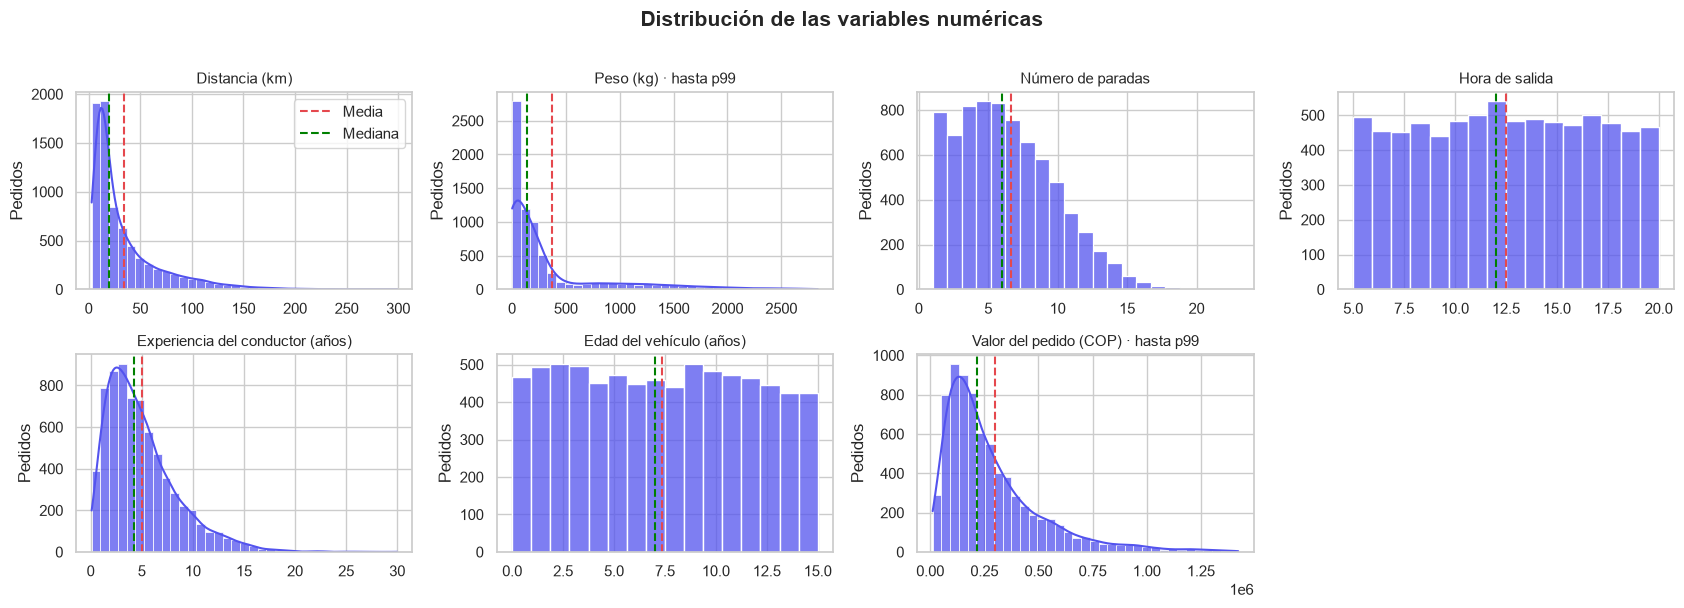

In [15]:
variables_num = ["distancia_km", "peso_kg", "num_paradas", "hora_salida",
                 "experiencia_conductor_anios", "edad_vehiculo_anios", "valor_pedido_COP"]
nombres = {"distancia_km": "Distancia (km)", "peso_kg": "Peso (kg)", "num_paradas": "Número de paradas",
           "hora_salida": "Hora de salida", "experiencia_conductor_anios": "Experiencia del conductor (años)",
           "edad_vehiculo_anios": "Edad del vehículo (años)", "valor_pedido_COP": "Valor del pedido (COP)"}

fig, axes = plt.subplots(2, 4, figsize=(17,6))
axes = axes.flatten()
for i, var in enumerate(variables_num):
    datos = df_eda[var].dropna()
    titulo = nombres[var]
    if var in ["peso_kg", "valor_pedido_COP"]:          # colas muy largas: mostramos hasta el percentil 99
        datos = datos[datos <= datos.quantile(0.99)]
        titulo += " · hasta p99"
    discreta = var in ["num_paradas", "hora_salida", "edad_vehiculo_anios"]
    sns.histplot(datos, bins=datos.nunique() if discreta else 35, kde=not discreta, ax=axes[i], color=MORADO, alpha=0.75)
    axes[i].axvline(df_eda[var].mean(), color=ROJO, linestyle="--", label="Media")
    axes[i].axvline(df_eda[var].median(), color="green", linestyle="--", label="Mediana")
    axes[i].set_title(titulo, fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Pedidos")
axes[0].legend()
axes[7].axis("off")
plt.suptitle("Distribución de las variables numéricas", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

#### Interpretación
- distancia_km: muy sesgada a la derecha. La mayoría de las rutas son cortas (mediana ~20 km), pero hay una cola larga de rutas de más de 100 km. Es una mezcla de tres mundos: urbano (corto), periurbano y rural (largo).
- peso_kg: también muy sesgada. Hay muchos pedidos livianos y unos pocos muy pesados (los de más de 3.000 kg son todos camiones, como vimos en 2.3).
- valor_pedido_COP: la mayoría de los pedidos vale entre $100.000 y $400.000, con una cola de pedidos grandes.
- hora_salida: casi uniforme entre las 5 y las 20 h: se despacha a todas horas.
- edad_vehiculo_anios: también casi uniforme entre 0 y 15 años.
- num_paradas: Con cola a la derecha, la mayoría entre 1 y 9 paradas.
- experiencia_conductor_anios: sesgada a la derecha: muchos conductores con pocos años y pocos con mucha experiencia.

### 2.4.2 Boxplots: valores atípicos

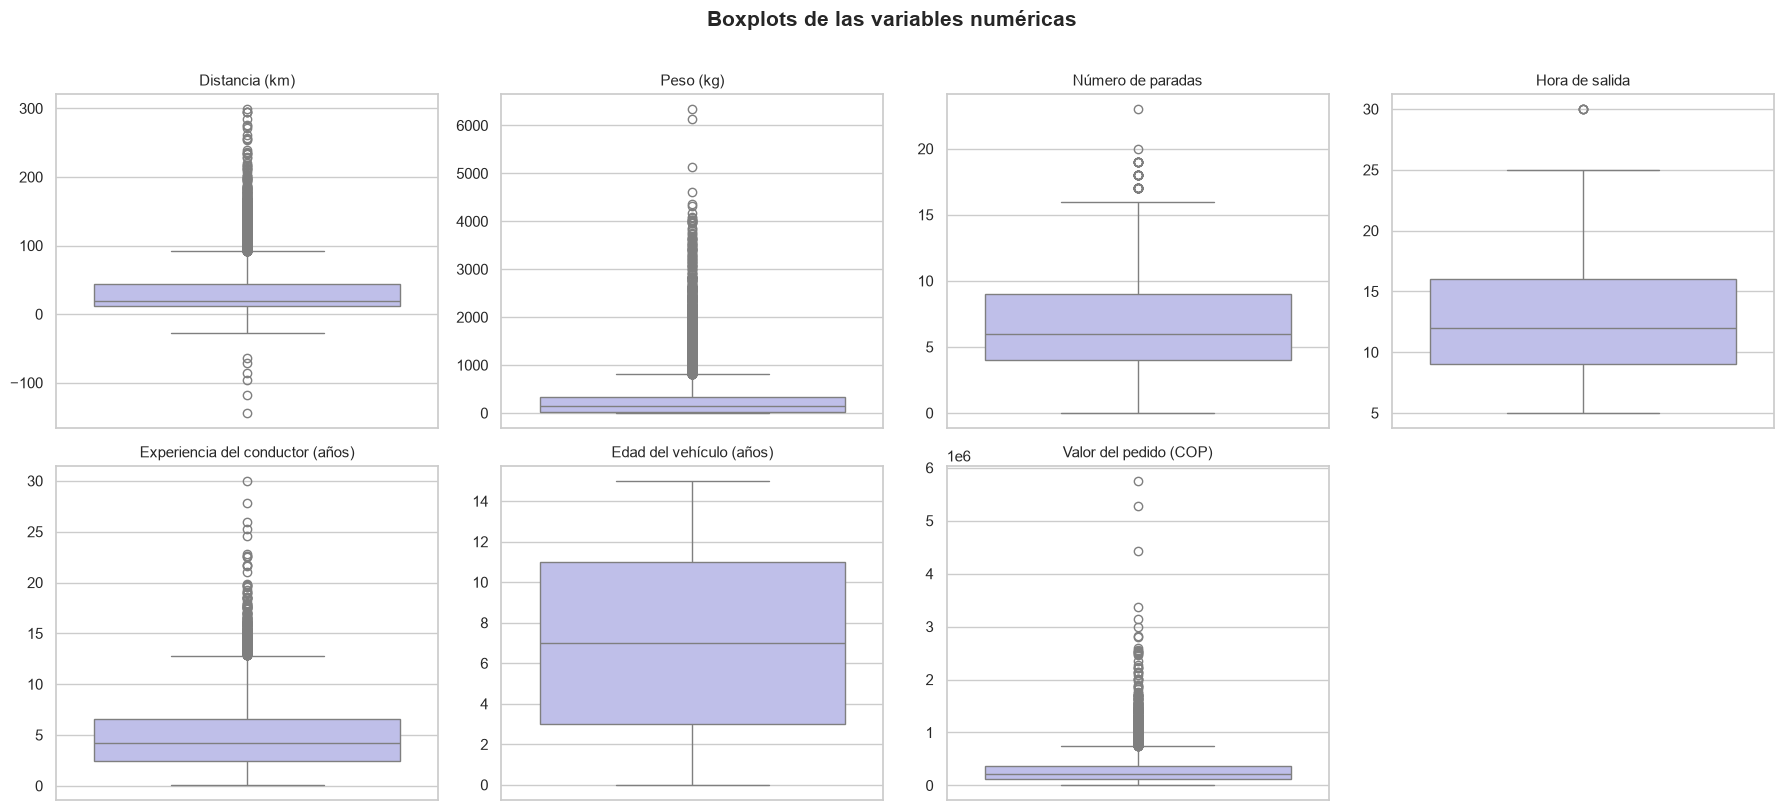

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, var in enumerate(variables_num):
    sns.boxplot(y=df[var], ax=axes[i], color=LILA)
    axes[i].set_title(nombres[var], fontsize=11)
    axes[i].set_ylabel("")
axes[7].axis("off")
plt.suptitle("Boxplots de las variables numéricas", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

#### Interpretación
- distancia_km, peso_kg y valor_pedido_COP tienen muchos puntos sueltos hacia arriba. Eso es esperable en parte (rutas rurales largas, camiones pesados, pedidos empresariales) y en parte son los valores sospechosos que ya anotamos (distancias > 200 km, motos con cientos de kilos).
- distancia_km también tiene puntos sueltos hacia abajo (hasta -144 km): son las distancias negativas de la sección 2.3.
- experiencia_conductor_anios tiene puntos sueltos hacia arriba (conductores muy experimentados, que no son un error).
- num_paradas tiene atípicos (puntos entre 17 y 23). hora_salida tiene un punto suelto en 30 (puede ser un error de digitación). Solo edad_vehiculo_anios no presenta valores atípicos.
- Tener un valor atípico no significa que sea un error: un camión con 5.000 kg o una ruta rural de 150 km son posibles, mientras que una moto que carga cientos de kilos (hay 25 con más de 100 kg) es sospechosa. Por eso solo tratamos como error los valores imposibles (Fase 3) y los sospechosos los dejamos sin modificar.

### 2.4.3 Asimetría y curtosis en números
Calculado con df_eda (sin duplicados y sin los valores imposibles).

In [17]:
resumen_forma = pd.DataFrame({
    "Media":     df_eda[variables_num].mean().round(2),
    "Mediana":   df_eda[variables_num].median().round(2),
    "Std":       df_eda[variables_num].std().round(2),
    "Mín":       df_eda[variables_num].min().round(2),
    "Máx":       df_eda[variables_num].max().round(2),
    "Asimetría": df_eda[variables_num].skew().round(2),
    "Curtosis":  df_eda[variables_num].kurtosis().round(2),
})
resumen_forma

,Media,Mediana,Std,Mín,Máx,Asimetría,Curtosis
distancia_km,34.37,19.5,35.99,2.9,299.0,2.27,6.68
peso_kg,371.06,143.7,617.05,1.5,6341.2,2.83,10.23
num_paradas,6.61,6.0,3.41,1.0,23.0,0.56,-0.02
hora_salida,12.51,12.0,4.57,5.0,20.0,-0.01,-1.18
experiencia_conductor_anios,4.98,4.2,3.48,0.1,30.0,1.36,2.65
edad_vehiculo_anios,7.36,7.0,4.58,0.0,15.0,0.03,-1.21
valor_pedido_COP,301391.92,215900.0,296078.41,11300.0,5752400.0,4.41,42.97


### Interpretación
- valor_pedido_COP tiene la mayor asimetría (≈ 4,4) y una curtosis enorme (≈ 43): una cola muy pesada, con pocos pedidos gigantes. La media (~$301.000) está bien por encima de la mediana (~$216.000), así que la mediana representa mejor al pedido típico.
- peso_kg (≈ 2,8) y distancia_km (≈ 2,3) también están claramente sesgadas a la derecha.
- experiencia_conductor_anios (≈ 1,4) está algo sesgada.
- hora_salida y edad_vehiculo_anios tienen asimetría cercana a 0: son simétricas.
- num_paradas tiene asimetría de 0,56: sesgo leve.
- Consecuencia para la Fase 3: en variables sesgadas, imputar los nulos con la mediana es mejor que con la media. También habrá que pensar cómo tratar las colas (por ejemplo, en la regresión logística y KNN, que son sensibles a escalas y extremos).

## 2.5 Análisis univariado categórico 

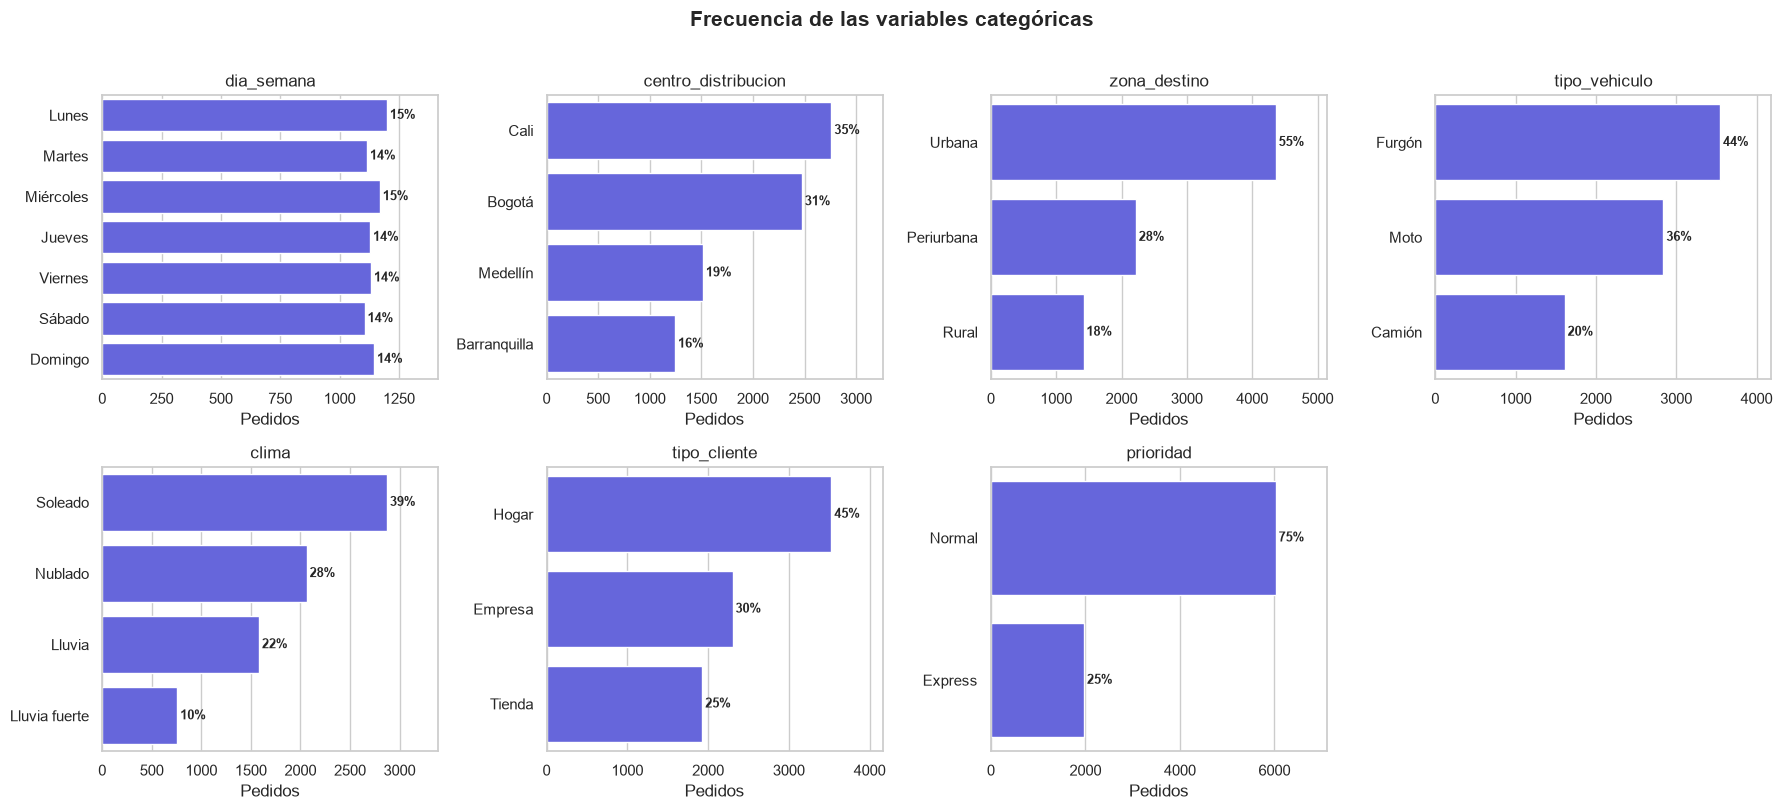

Nulos que hay en las categóricas (clima y tipo_cliente):
clima           720
tipo_cliente    240


In [18]:
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
orden_clima = ["Soleado", "Nublado", "Lluvia", "Lluvia fuerte"]
categoricas = ["dia_semana", "centro_distribucion", "zona_destino", "tipo_vehiculo",
               "clima", "tipo_cliente", "prioridad"]
ordenes = {"dia_semana": orden_dias, "clima": orden_clima}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for ax, var in zip(axes, categoricas):
    orden = ordenes.get(var, df_eda[var].value_counts().index.tolist())
    conteo = df_eda[var].value_counts().reindex(orden)
    sns.barplot(x=conteo.values, y=conteo.index, ax=ax, color=MORADO, orient="h")
    for j, v in enumerate(conteo.values):
        ax.text(v + conteo.max() * 0.01, j, f"{v/ conteo.sum()*100:.0f}%", va="center", fontsize=9, fontweight="bold")
    ax.set_title(var)
    ax.set_xlabel("Pedidos")
    ax.set_ylabel("")
    ax.set_xlim(0, conteo.max() * 1.18)
axes[7].axis("off")
plt.suptitle("Frecuencia de las variables categóricas", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

print("Nulos que hay en las categóricas (clima y tipo_cliente):")
print(df_eda[["clima", "tipo_cliente"]].isna().sum().to_string())

###  Interpretación
- Día de la semana: casi parejo (cada día entre 14 % y 15 %); se despacha todos los días de la semana, incluso domingos.
- Centro de distribución: Cali (35 %) y Bogotá (31 %) concentran dos tercios de los pedidos; Medellín (19 %) y Barranquilla (16 %) son más pequeños.
- Zona de destino: más de la mitad de los pedidos son urbanos (55 %); periurbanos 28 %; rurales 18 %.
- Tipo de vehículo: furgón el más usado (44 %), luego moto (36 %) y camión (20 %).
- Clima (entre los pedidos con clima registrado): predomina el soleado (~39 %) y el nublado (~28 %); hay ~22 % de lluvia y un 10 % de lluvia fuerte.
- Tipo de cliente (sin contar los nulos): Hogar 45 %, Empresa 30 %, Tienda 25 %.
- Prioridad: 3 de cada 4 pedidos son normales (75 %) y 1 de cada 4 es Express (25 %).

## 2.6 Balance de clases de la variable objetivo 
Antes de modelar hay que saber cuántos pedidos llegan tarde: si la clase "tarde" es minoritaria, el accuracy puede engañar.

,pedidos,%
entrega_tardia,,
No,5513,68.6
Sí,2522,31.4


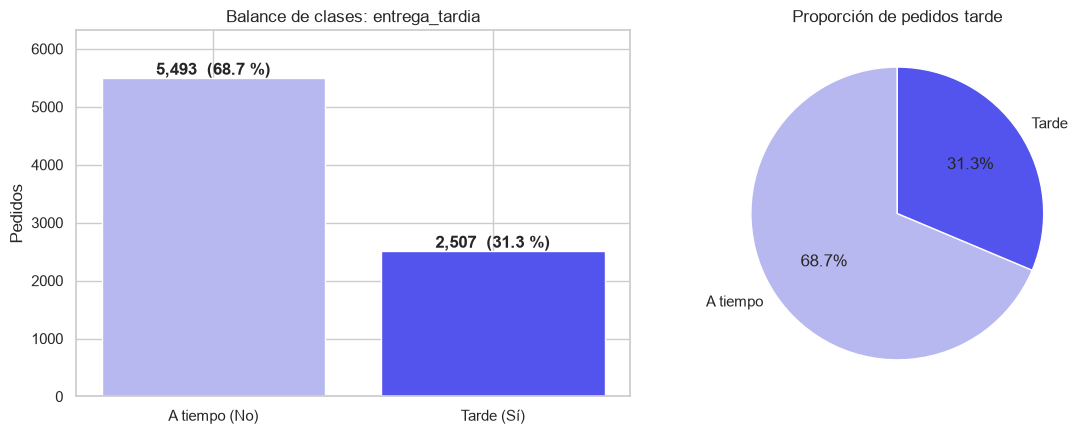

Tasa de retraso: 31.3 %  (1 de cada 3.2 pedidos)
Un modelo 'tonto' que diga SIEMPRE 'a tiempo' tendría accuracy de 68.7 % y recall de 0 %


In [19]:
balance = pd.DataFrame({
    "pedidos": df["entrega_tardia"].value_counts(),
    "%": (df["entrega_tardia"].value_counts(normalize=True) * 100).round(1),
})
display(balance)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
orden = ["No", "Sí"]
conteo = df_eda["entrega_tardia"].value_counts().reindex(orden)
ejes[0].bar(["A tiempo (No)", "Tarde (Sí)"], conteo.values, color=[LILA, MORADO])
for i, v in enumerate(conteo.values):
    ejes[0].text(i, v + 60, f"{v:,}  ({v/len(df_eda)*100:.1f} %)", ha="center", fontweight="bold")
ejes[0].set_title("Balance de clases: entrega_tardia")
ejes[0].set_ylabel("Pedidos")
ejes[0].set_ylim(0, conteo.max() * 1.15)

ejes[1].pie(conteo.values, labels=["A tiempo", "Tarde"], colors=[LILA, MORADO], autopct="%1.1f%%",
            startangle=90, wedgeprops={"edgecolor": "white"})
ejes[1].set_title("Proporción de pedidos tarde")
plt.tight_layout()
plt.show()

tasa_tarde = df_eda["tarde"].mean()
print(f"Tasa de retraso: {tasa_tarde*100:.1f} %  (1 de cada {1/tasa_tarde:.1f} pedidos)")
print(f"Un modelo 'tonto' que diga SIEMPRE 'a tiempo' tendría accuracy de {(1-tasa_tarde)*100:.1f} % y recall de 0 %")

### Interpretación
- 2.507 de 8.000 pedidos (31,3 %) llegaron tarde; coincide con el "cerca de 3 de cada 10" del caso (en la base original sin limpiar es 31,4 %).
- Las clases están moderadamente desbalanceadas: ~69 % a tiempo y ~31 % tarde. No es un desbalance extremo, pero sí lo suficiente para ser cuidadosos.
- Línea base: un modelo "tonto" que diga siempre "a tiempo" ya tendría 68,7 % de accuracy sin aprender nada, pero 0 % de recall, y no detectaría ningún retraso. Por eso en las siguientes fases el accuracy solo no sirve y juzgamos los modelos por recall, precision y F1 de la clase "tarde", como definimos en la Fase 1.
- Por el nivel de desbalance, en la división train/test usaremos stratify=y para que ambos conjuntos tengan la misma proporción de retrasos.

---
## 2.7 Análisis bivariado: ¿qué se relaciona con llegar tarde? 

Para cada variable calculamos el % de pedidos que llegan tarde en cada grupo. La línea punteada de los gráficos es el promedio general (31,3 %): los grupos por encima de la línea son de mayor riesgo.

### 2.7.1 Variables categóricas vs. retraso (gráficos 1 a 7)

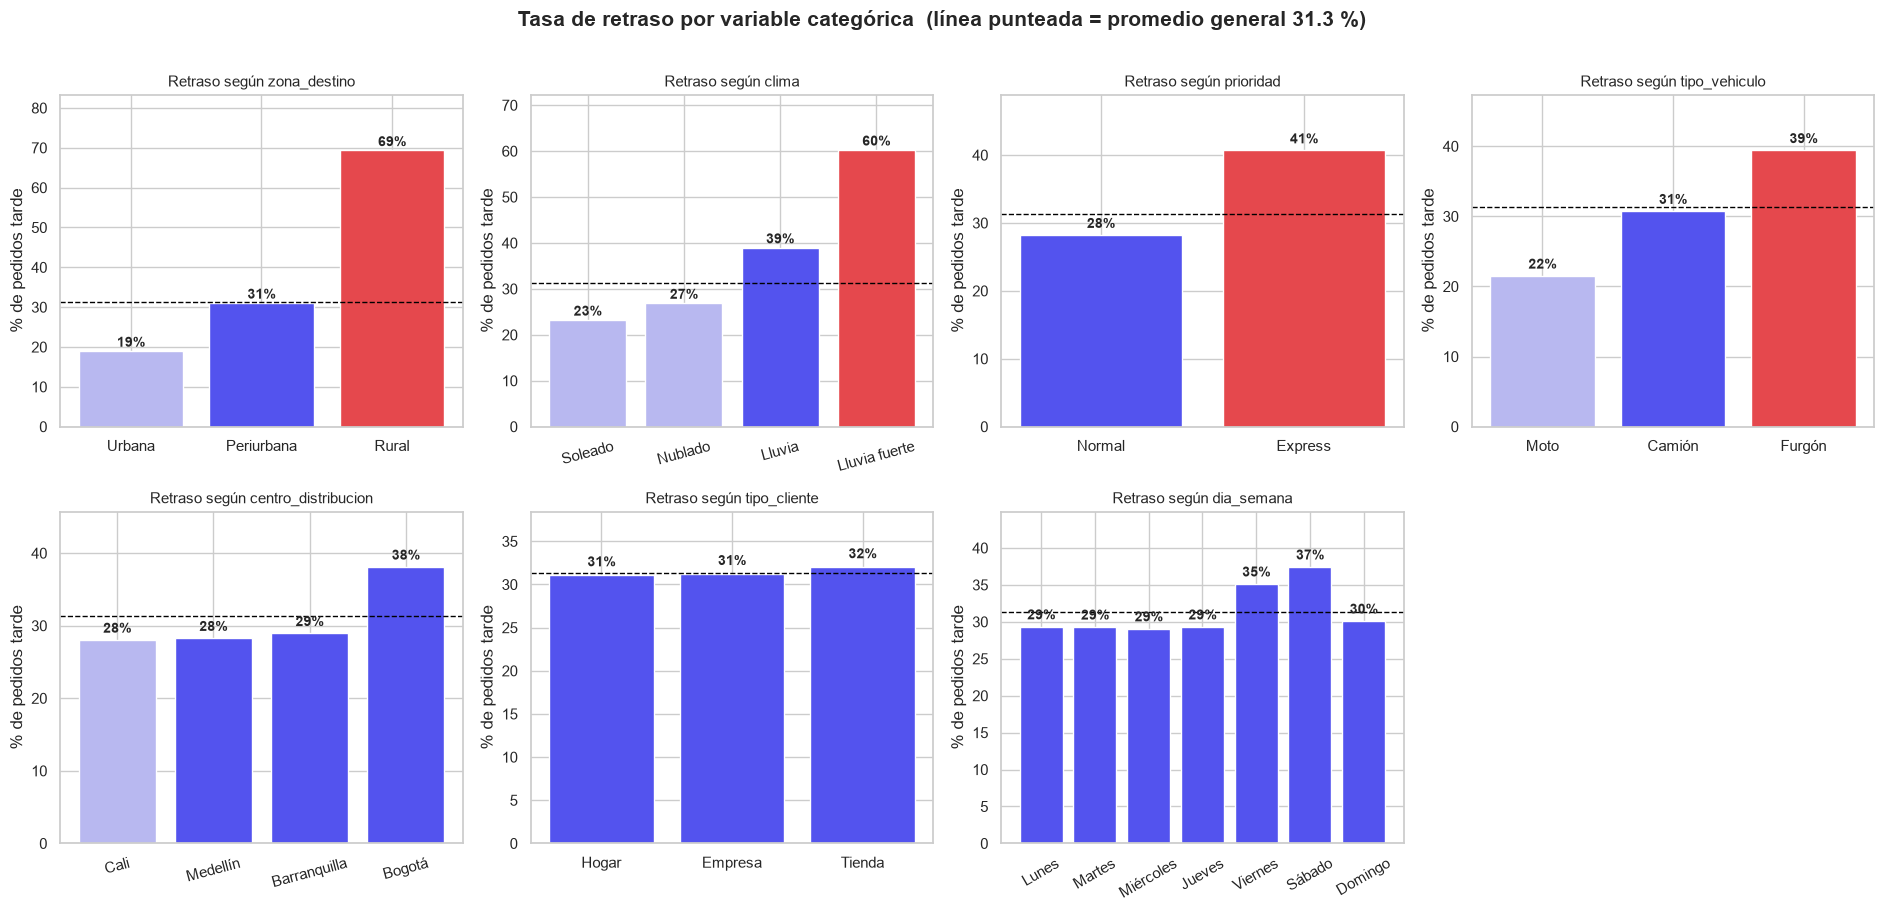

In [20]:
# La variable objetivo en 0/1 (columna "tarde") ya está en df_eda
tasa_global = df_eda["tarde"].mean() * 100

def grafico_tasa(var, ax, orden=None, rotar=0):
    t = (df_eda.groupby(var, observed=True)["tarde"].mean() * 100)
    t = t.reindex(orden) if orden is not None else t.sort_values(ascending=False)
    colores = [ROJO if v > tasa_global * 1.25 else MORADO if v > tasa_global * 0.9 else LILA for v in t.values]
    ax.bar(t.index.astype(str), t.values, color=colores)
    for i, v in enumerate(t.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold", fontsize=10)
    ax.axhline(tasa_global, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Retraso según {var}", fontsize=11)
    ax.set_ylabel("% de pedidos tarde")
    ax.set_xlabel("")
    ax.set_ylim(0, max(t.values) * 1.2)
    ax.tick_params(axis="x", rotation=rotar)

fig, axes = plt.subplots(2, 4, figsize=(19, 9))
axes = axes.flatten()
grafico_tasa("zona_destino", axes[0], ["Urbana", "Periurbana", "Rural"])
grafico_tasa("clima", axes[1], orden_clima, rotar=15)
grafico_tasa("prioridad", axes[2], ["Normal", "Express"])
grafico_tasa("tipo_vehiculo", axes[3], ["Moto", "Camión", "Furgón"])
grafico_tasa("centro_distribucion", axes[4], ["Cali", "Medellín", "Barranquilla", "Bogotá"], rotar=15)
grafico_tasa("tipo_cliente", axes[5], ["Hogar", "Empresa", "Tienda"])
grafico_tasa("dia_semana", axes[6], orden_dias, rotar=30)
axes[7].axis("off")
plt.suptitle(f"Tasa de retraso por variable categórica  (línea punteada = promedio general {tasa_global:.1f} %)",
             y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [21]:
print("% de pedidos por zona dentro de cada centro:")
display((pd.crosstab(df_eda["centro_distribucion"], df_eda["zona_destino"], normalize="index") * 100).round(1))

print("% de pedidos por clima dentro de cada centro:")
display((pd.crosstab(df_eda["centro_distribucion"], df_eda["clima"], normalize="index") * 100).round(1))

% de pedidos por zona dentro de cada centro:


zona_destino,Periurbana,Rural,Urbana
centro_distribucion,,,
Barranquilla,27.6,18.0,54.4
Bogotá,27.9,17.7,54.3
Cali,26.8,18.0,55.2
Medellín,29.3,16.9,53.7


% de pedidos por clima dentro de cada centro:


clima,Lluvia,Lluvia fuerte,Nublado,Soleado
centro_distribucion,,,,
Barranquilla,22.8,10.1,29.6,37.5
Bogotá,22.5,10.2,28.1,39.2
Cali,20.4,10.6,29.2,39.7
Medellín,22.0,10.7,26.3,41.0


#### Interpretación 
1. Zona de destino: la variable categórica con más separación. Rural: 69 % de retraso, periurbana 31 %, urbana 19 %. Un pedido rural tiene más de 3 veces más riesgo que uno urbano.
2. Clima: la lluvia fuerte lleva el retraso a 60 %, la lluvia a 39 %, mientras que con sol es 23 % y nublado 27 %. El riesgo sube de forma escalonada con la intensidad de la lluvia.
3. Prioridad: los pedidos Express llegan tarde 41 % de las veces vs. 28 % de los Normales. Tiene sentido: su ventana de entrega es más corta y es más fácil incumplirla.
4. Tipo de vehículo: las motos son las más puntuales (22 %); el furgón el peor (39 %); el camión queda en medio (31 %).
5. Centro de distribución: Bogotá se destaca con 38 %, mientras que Cali, Medellín y Barranquilla están alrededor de 28 %-29 %. Los cuatro centros tienen casi la misma mezcla de zonas y de clima (tablas de arriba), así que la diferencia de Bogotá no se explica por eso. Podría deberse a algo propio de ese centro (por ejemplo, el tráfico), pero los datos no nos permiten comprobarlo.
6. Tipo de cliente: Hogar (31 %), Empresa (31 %) y Tienda (32 %) son prácticamente iguales: esta variable casi no aporta información sobre el retraso.
7. Día de la semana: de lunes a jueves el retraso es 29 %, pero viernes (35 %) y sábado (37 %) son claramente peores. El domingo vuelve a ~30 %.

### 2.7.2 Distancia vs. retraso 

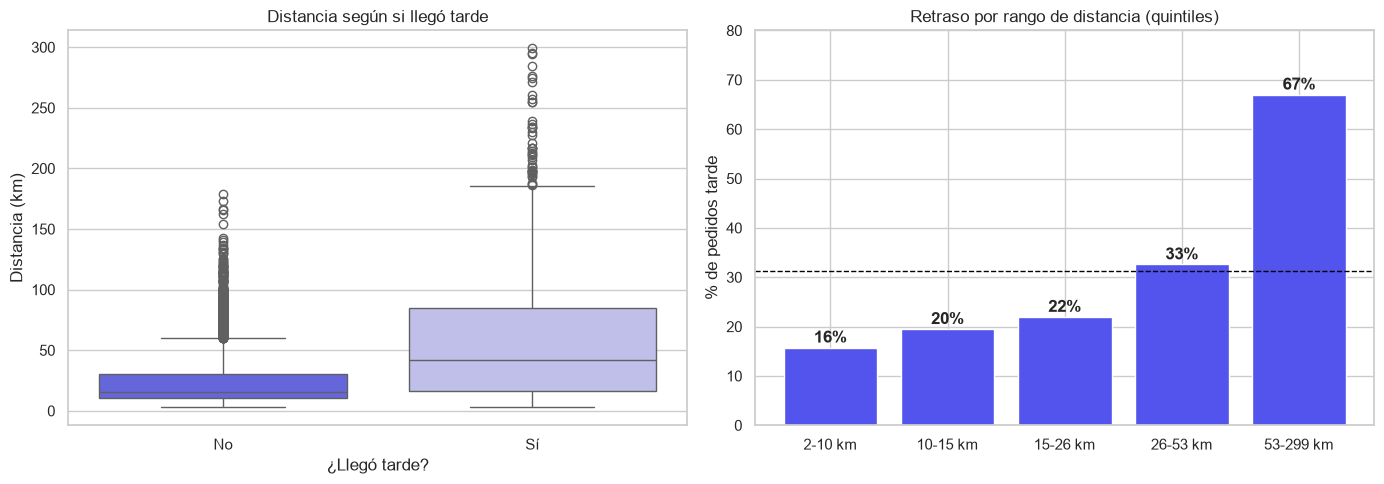

entrega_tardia
No    15.9
Sí    41.8


In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_eda, x="entrega_tardia", y="distancia_km", order=["No", "Sí"], palette=[LILA, MORADO],
            hue="entrega_tardia", legend=False, ax=ejes[0])
ejes[0].set_title("Distancia según si llegó tarde")
ejes[0].set_xlabel("¿Llegó tarde?")
ejes[0].set_ylabel("Distancia (km)")

cortes = pd.qcut(df_eda["distancia_km"], 5)
tasa = df_eda.groupby(cortes, observed=True)["tarde"].mean() * 100
etiquetas = [f"{int(i.left)}-{int(i.right)} km" for i in tasa.index]
ejes[1].bar(etiquetas, tasa.values, color=MORADO)
for i, v in enumerate(tasa.values):
    ejes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold")
ejes[1].axhline(tasa_global, color="black", linestyle="--", linewidth=1)
ejes[1].set_title("Retraso por rango de distancia (quintiles)")
ejes[1].set_ylabel("% de pedidos tarde")
ejes[1].set_ylim(0, 80)
plt.tight_layout()
plt.show()

print(df_eda.groupby("entrega_tardia")["distancia_km"].median().round(1).rename("Mediana de distancia (km)").to_string())

#### Interpretación
- Gráfico 8 (boxplot): los pedidos tarde recorren distancias mucho mayores: mediana de ~42 km contra ~16 km de los puntuales.
- Gráfico 9 (quintiles): el riesgo crece con la distancia y se dispara en el último tramo: del 16 % en las rutas de hasta 10 km, a 67 % en las de más de 53 km. No es una línea recta: a partir de unos 53 km es más probable llegar tarde que a tiempo.
- La distancia es la variable numérica más relacionada con el retraso.

### 2.7.3 Hora de salida vs. retraso (gráfico 10)
La guía pide pensar si el efecto de la hora es lineal. Lo miramos hora por hora.

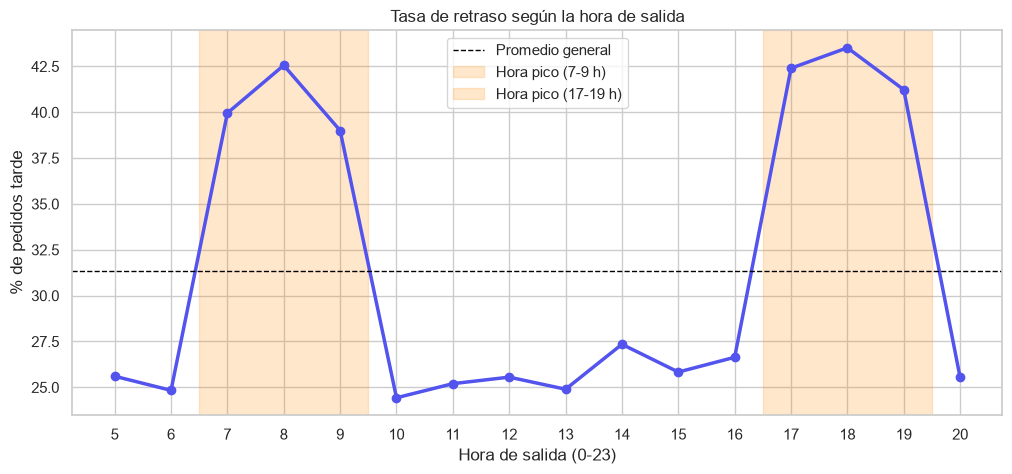

Retraso en horas pico (7-9 y 17-19): 41.5 %
Retraso fuera de hora pico:           25.6 %
Horas fuera de 0-23 en la base original (ya convertidas a nulo en df_eda): [25.0, 30.0]


In [23]:
# Solo horas válidas (0 a 23): las 25 y 30 eran errores de digitación y en df_eda ya son nulos
horas_validas = df_eda[df_eda["hora_salida"].between(0, 23)]
por_hora = horas_validas.groupby("hora_salida")["tarde"].mean() * 100

plt.figure(figsize=(12, 5))
plt.plot(por_hora.index, por_hora.values, marker="o", color=MORADO, linewidth=2.5)
plt.axhline(tasa_global, color="black", linestyle="--", linewidth=1, label="Promedio general")
plt.axvspan(6.5, 9.5, color=NARANJA, alpha=0.2, label="Hora pico (7-9 h)")
plt.axvspan(16.5, 19.5, color=NARANJA, alpha=0.2, label="Hora pico (17-19 h)")
plt.title("Tasa de retraso según la hora de salida")
plt.xlabel("Hora de salida (0-23)")
plt.ylabel("% de pedidos tarde")
plt.xticks(range(5, 21))
plt.legend()
plt.show()

pico = horas_validas["hora_salida"].isin([7, 8, 9, 17, 18, 19])
print(f"Retraso en horas pico (7-9 y 17-19): {horas_validas.loc[pico, 'tarde'].mean()*100:.1f} %")
print(f"Retraso fuera de hora pico:           {horas_validas.loc[~pico, 'tarde'].mean()*100:.1f} %")
print("Horas fuera de 0-23 en la base original (ya convertidas a nulo en df_eda):", sorted(df.loc[df['hora_salida'] > 23, 'hora_salida'].unique().tolist()))

#### Interpretación
La relación no es lineal: no es "mientras más tarde, más riesgo". Hay dos picos claros que coinciden con las horas pico del tráfico: de 7 a 9 h y de 17 a 19 h, donde el retraso sube a 39 %-43 %. Fuera de esas franjas se queda en ~25-26 %.

Esto explica por qué la correlación lineal de hora_salida con el retraso es casi cero (0,03) aunque la hora sí importa: una recta no puede describir dos picos. Para la Fase 3-4 conviene crear una variable de "hora pico" (sí/no): un árbol de decisión puede capturar esos tramos solo, pero una regresión logística no.

## 2.8 Matriz de correlaciones 
Calculamos la correlación de Pearson entre las variables numéricas y la variable objetivo (codificada como 1 = tarde, 0 = a tiempo).

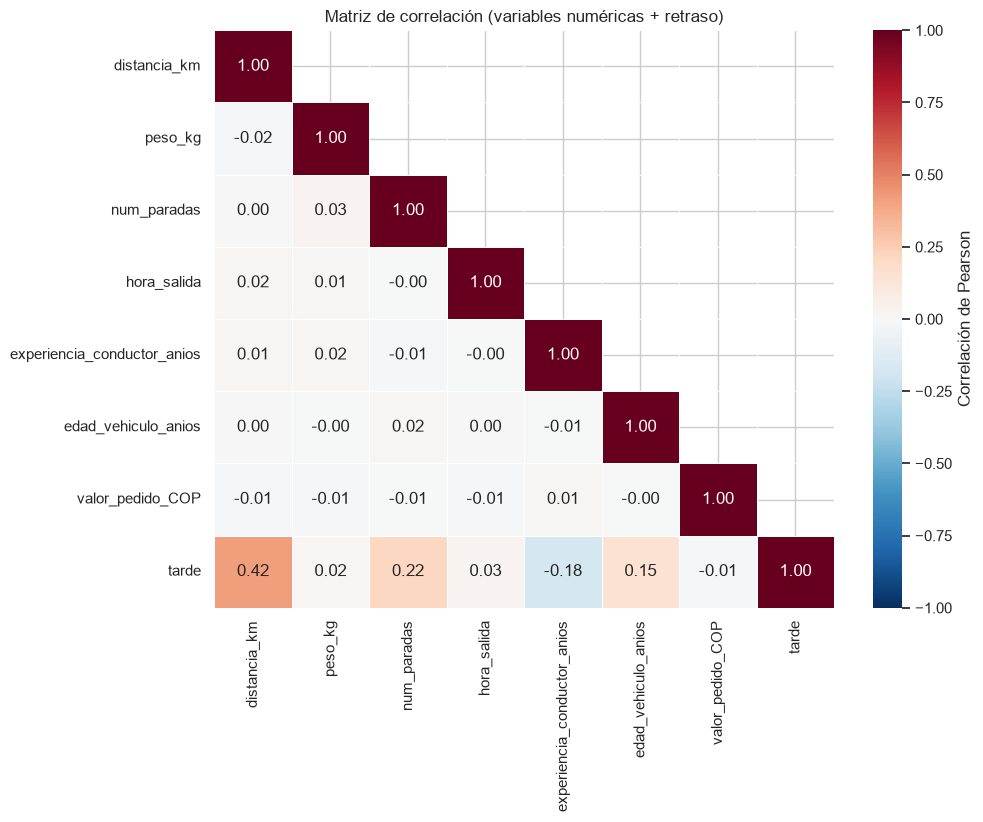

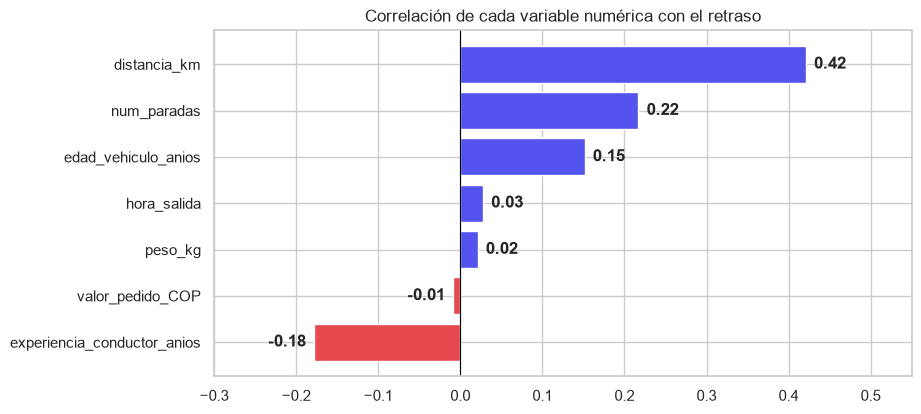

Correlación más alta entre dos variables explicativas (en valor absoluto): 0.03


In [24]:
cols_corr = variables_num + ["tarde"]
corr = df_eda[cols_corr].corr()

plt.figure(figsize=(10, 7.5))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlación de Pearson"})
plt.title("Matriz de correlación (variables numéricas + retraso)")
plt.show()

corr_objetivo = corr["tarde"].drop("tarde").sort_values()
plt.figure(figsize=(9, 4.5))
plt.barh(corr_objetivo.index, corr_objetivo.values, color=[ROJO if v < 0 else MORADO for v in corr_objetivo.values])
for i, v in enumerate(corr_objetivo.values):
    plt.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontweight="bold")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de cada variable numérica con el retraso")
plt.xlim(-0.3, 0.55)
plt.show()

print("Correlación más alta entre dos variables explicativas (en valor absoluto):",
      corr.drop(index="tarde", columns="tarde").where(~np.eye(len(variables_num), dtype=bool)).abs().max().max().round(2))

### Interpretación
- Con el retraso:
  - distancia_km es la más fuerte, con 0,42: a mayor distancia, más retraso.
  - num_paradas 0,22: más paradas, más retraso.
  - experiencia_conductor_anios -0,18: más experiencia, menos retraso (es negativa, lo que es bueno).
  - edad_vehiculo_anios 0,15: vehículos más viejos, más retraso.
  - hora_salida (0,03), peso_kg (0,02) y valor_pedido_COP (-0,01) tienen correlación casi nula.
- Entre las variables explicativas: las correlaciones son prácticamente cero (la más alta es ~0,03). No hay multicolinealidad entre las numéricas, lo cual es bueno para modelos como la regresión logística.
- valor_pedido_COP casi no tiene relación lineal con el retraso ni con las otras numéricas: es poco probable que aporte al modelo.

## 2.9 Respuesta preliminar a la pregunta de negocio

Volvemos a la pregunta de la Fase 1: con la información disponible al momento del despacho, ¿podemos predecir si un pedido llegará tarde? ¿Qué condiciones de la operación aumentan el riesgo?

### ¿Se puede predecir?

Todo indica que vale la pena intentarlo, pero la confirmación la hacemos en las Fases 4 y 5 con recall, precision y F1. Por ahora, el EDA nos deja dos cosas claras:

- Hay señal en los datos. El promedio general de retraso es 31,3 %, y varias variables separan bien a los pedidos puntuales de los atrasados. Por ejemplo, la mediana de distancia es ~42 km en los pedidos tarde contra ~16 km en los puntuales.
- Las variables sirven para el momento del despacho. Distancia, zona, vehículo, hora de salida, clima, prioridad, paradas, experiencia del conductor y edad del vehículo se conocen antes de que salga el pedido, que es justo lo que pide la gerencia.

### ¿Qué condiciones aumentan el riesgo?

| Condición | Lo que vimos | Dónde |
|---|---|---|
| Zona rural | 69 % de retraso (urbana 19 %, periurbana 31 %) | 2.7.1 |
| Distancia larga | Sube de 16 % (2-10 km) a 67 % (más de 53 km); es la variable numérica más fuerte (correlación 0,42) | 2.7.2 y 2.8 |
| Lluvia | Lluvia fuerte 60 %, lluvia 39 %, nublado 27 %, soleado 23 % | 2.7.1 |
| Hora pico de salida (7-9 h y 17-19 h) | 41,5 % contra 25,6 % fuera de pico | 2.7.3 |
| Prioridad Express | 41 % contra 28 % de los Normales | 2.7.1 |
| Furgón | 39 % (moto 22 %, camión 31 %) | 2.7.1 |
| Centro de Bogotá | 38 % (Cali 28 %, Medellín 28 %, Barranquilla 29 %) | 2.7.1 |
| Viernes y sábado | 35 % y 37 % (lunes a jueves ~29 %, domingo 30 %) | 2.7.1 |
| Más paradas | Correlación 0,22 | 2.8 |
| Conductor con poca experiencia | Correlación -0,18 (a más experiencia, menos retraso) | 2.8 |
| Vehículo más viejo | Correlación 0,15 | 2.8 |

Por el contrario, el tipo de cliente (Hogar 31 %, Empresa 31 %, Tienda 32 %) y el valor del pedido (correlación -0,01) casi no cambian el riesgo.

### Algo para tener presente

Estos resultados miran una variable a la vez. Qué tanto pesa cada una cuando se combinan, y qué tan bien se puede predecir, lo responden los modelos de las Fases 4 y 5.

---
# FASE 3 · Preparación de los datos

Antes de modelar hay que dejar la base lista. Varias tareas de esta fase ya las resolvimos en la Fase 2, así que no las repetimos:

| Tarea de la Fase 3 | ¿Dónde se resolvió? |
|---|---|
| Eliminar duplicados (35 filas) | Sección 2.3, en df_eda |
| Estandarizar centro_distribucion y tipo_vehiculo | Sección 2.3, en df_eda |
| Detectar valores imposibles y decidir qué hacer | Sección 2.3: los imposibles se volvieron nulos y se imputan aquí |
| Los sospechosos (distancias > 200 km, motos de más de 100 kg, valores altos) | Se dejan sin modificar, por decisión del grupo |

**Lo que falta, y desarrollamos en esta fase:**
1. Tratar los nulos y justificar la estrategia de cada columna.
2. Dividir en entrenamiento y prueba (70 % / 30 %, con stratify=y y random_state=42).
3. Crear la variable hora_pico.
4. Codificar las categóricas con get_dummies.
5. Escalar las variables para la regresión logística.
6. Guardar la base limpia en un CSV.

## 3.1 Punto de partida: los nulos que tenemos ahora

Importamos las librerías de modelado y hacemos una copia de df_eda para trabajar (df_limpio), siguiendo la recomendación de la profe de no tocar la base original. Los nulos de esta tabla incluyen los valores imposibles que convertimos a nulo en la sección 2.3.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42   

In [26]:
# Copia de trabajo para modelar 
df_limpio = df_eda.copy()

nulos_modelo = pd.DataFrame({
    "nulos": df_limpio.isna().sum(),
    "% del total": (df_limpio.isna().mean() * 100).round(1),
})
nulos_modelo = nulos_modelo[nulos_modelo["nulos"] > 0].sort_values("nulos", ascending=False)
display(nulos_modelo)
print(f"Filas: {len(df_limpio)} | filas con al menos un nulo: {df_limpio.isna().any(axis=1).sum()} ({df_limpio.isna().any(axis=1).mean()*100:.1f} %)")

,nulos,% del total
experiencia_conductor_anios,880,11.0
clima,720,9.0
peso_kg,655,8.2
edad_vehiculo_anios,560,7.0
num_paradas,539,6.7
distancia_km,420,5.2
valor_pedido_COP,400,5.0
hora_salida,330,4.1
tipo_cliente,240,3.0


Filas: 8000 | filas con al menos un nulo: 3629 (45.4 %)


### Interpretación
Las nueve columnas con nulos son las mismas de la Fase 2, pero algunas subieron: peso_kg, num_paradas, distancia_km y hora_salida tienen ahora más nulos porque les sumamos los valores imposibles (peso 0, 0 paradas, distancias negativas u horas mayores a 23). Después de quitar los duplicados quedan 8.000 pedidos, y 3.629 de ellos (45,4 %) tienen al menos un nulo.

Por eso no eliminamos filas con nulos: perderíamos casi la mitad de la base, incluyendo muchos pedidos que ya están completos en las demás variables. Decidimos imputar.

## 3.2 Estrategia de imputación, columna por columna

| Columna | % nulos | Estrategia | Por qué |
|---|---|---|---|
| experiencia_conductor_anios | 11,0 % | **Mediana** | Es sesgada a la derecha (asimetría ≈ 1,4): unos pocos conductores muy experimentados jalarían la media hacia arriba. La mediana representa mejor al conductor típico. |
| peso_kg | 8,2 % | **Mediana** | Muy sesgada (asimetría ≈ 2,8) por los camiones y los pedidos pesados. La media (≈ 371 kg) no representa a la mayoría. |
| edad_vehiculo_anios | 7,0 % | **Mediana** | Es simétrica, así que media y mediana casi coinciden; la mediana da un valor entero, que es un dato posible. |
| num_paradas | 6,7 % | **Mediana** | Es discreta: la mediana (6) es un número de paradas posible; la media (6,6) no. |
| distancia_km | 5,2 % | **Mediana** | Sesgada (asimetría ≈ 2,3) por las rutas rurales largas. |
| valor_pedido_COP | 5,0 % | **Mediana** | Es la más sesgada de todas (asimetría ≈ 4,4): la media ($301.000) está muy por encima del pedido típico ($216.000). |
| hora_salida | 4,1 % | **Mediana** | Es discreta y simétrica; la mediana es una hora real del día (12 h). |
| tipo_cliente | 3,0 % | **Moda** | Es categórica: se usa la categoría más frecuente (Hogar). El tipo de cliente casi no cambia el riesgo (31 %-32 % en los tres), así que el error que se introduce es pequeño. |
| clima | 9,0 % | **Nueva categoría "Sin dato"** | Con la moda le asignaríamos "Soleado" a un 9 % de pedidos que en realidad podrían tener lluvia, y subestimaríamos su riesgo. Con "Sin dato" no inventamos información. |

**Dos decisiones adicionales:**
- Imputamos después de dividir en entrenamiento y prueba. Las medianas y la moda se calculan solo con el conjunto de entrenamiento y luego se aplican a los dos conjuntos. Así la prueba no influye en nada de lo que el modelo aprende (evitamos la fuga de datos).
- No creamos columnas de "dato faltante", porque en la Fase 2 vimos que los nulos no parecen estar relacionados con el retraso (no cambian su tasa).

**Limitación que reconocemos:** una mediana global no es lo ideal en peso_kg ni en distancia_km, porque dependen mucho del vehículo y de la zona. Imputar la mediana por grupo habría sido más organizado, pero preferimos una estrategia simple, que podamos explicar y justificar.

## 3.3 División en entrenamiento y prueba (70 % / 30 %)

Separamos las variables que no entran al modelo: id_pedido (es solo un código), fecha_despacho (el día de la semana ya está en dia_semana) y las dos versiones de la variable objetivo, para no meter la respuesta dentro de las variables de entrada. Usamos stratify=y por el desbalance (≈ 31 % tarde) y random_state=42.

In [ ]:
# Variables que no entran al modelo: identificador, fecha y las dos versiones de la variable objetivo
excluidas = ["id_pedido", "fecha_despacho", "entrega_tardia", "tarde"]
X = df_limpio.drop(columns=excluidas)
y = df_limpio["tarde"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)

print("Entrenamiento:", X_train.shape, "| % tarde:", round(y_train.mean() * 100, 1))
print("Prueba:       ", X_test.shape,  "| % tarde:", round(y_test.mean() * 100, 1))
print("Columnas que entran al modelo:", list(X.columns))

Entrenamiento: (5600, 14) | % tarde: 31.3
Prueba:        (2400, 14) | % tarde: 31.3
Columnas que entran al modelo: ['dia_semana', 'centro_distribucion', 'zona_destino', 'tipo_vehiculo', 'distancia_km', 'peso_kg', 'num_paradas', 'hora_salida', 'clima', 'experiencia_conductor_anios', 'edad_vehiculo_anios', 'tipo_cliente', 'prioridad', 'valor_pedido_COP']


### Interpretación
Quedan 5.600 pedidos para entrenar y 2.400 para probar, y en los dos conjuntos el porcentaje de retraso es el mismo (31,3 %), así que la prueba es justa. Al modelo entran 14 variables; ni el identificador, ni la fecha, ni la variable objetivo están entre ellas.

## 3.4 Imputación de nulos con las estadísticas del entrenamiento

In [ ]:
# Las estadísticas de imputación se calculan solo con entrenamiento
cols_mediana = ["distancia_km", "peso_kg", "valor_pedido_COP", "experiencia_conductor_anios",
                "num_paradas", "hora_salida", "edad_vehiculo_anios"]
medianas = X_train[cols_mediana].median()
moda_cliente = X_train["tipo_cliente"].mode()[0]

print("Medianas (calculadas con entrenamiento):")
print(medianas.round(1).to_string())
print("Moda de tipo_cliente:", moda_cliente)

def imputar(X_):
    X_ = X_.copy()
    X_[cols_mediana] = X_[cols_mediana].fillna(medianas)
    X_["tipo_cliente"] = X_["tipo_cliente"].fillna(moda_cliente)
    X_["clima"] = X_["clima"].fillna("Sin dato")
    return X_

X_train_imp = imputar(X_train)
X_test_imp = imputar(X_test)

print()
print("Nulos que quedan -> entrenamiento:", int(X_train_imp.isna().sum().sum()), "| prueba:", int(X_test_imp.isna().sum().sum()))
print("Categorías de clima ahora:", sorted(X_train_imp["clima"].unique().tolist()))

Medianas (calculadas con entrenamiento):
distancia_km                       19.4
peso_kg                           144.6
valor_pedido_COP               214500.0
experiencia_conductor_anios         4.1
num_paradas                         6.0
hora_salida                        12.0
edad_vehiculo_anios                 7.0
Moda de tipo_cliente: Hogar

Nulos que quedan -> entrenamiento: 0 | prueba: 0
Categorías de clima ahora: ['Lluvia', 'Lluvia fuerte', 'Nublado', 'Sin dato', 'Soleado']


### Interpretación
Las medianas salen del conjunto de entrenamiento: distancia 19,4 km, peso 144,6 kg, valor $214.500, experiencia 4,1 años, 6 paradas, salida a las 12 h y vehículo de 7 años. La moda de tipo_cliente es Hogar. Después de imputar no quedan nulos ni en entrenamiento ni en prueba, y clima pasa a tener cinco categorías, incluida "Sin dato".

## 3.5 Nueva variable: hora pico

En la Fase 2 vimos que el efecto de la hora no es lineal: el retraso sube en las horas pico (7-9 h y 17-19 h) y baja el resto del día, y por eso la correlación lineal con hora_salida es casi cero. Un modelo lineal no puede capturar dos picos con una sola recta, así que creamos hora_pico (1 si la salida es en hora pico, 0 si no) y dejamos también hora_salida para comparar cómo la usa cada modelo.

In [30]:
# Variable nueva: hora pico (7-9 h y 17-19 h), porque el efecto de la hora no es lineal
horas_pico = [7, 8, 9, 17, 18, 19]
X_train_imp["hora_pico"] = X_train_imp["hora_salida"].isin(horas_pico).astype(int)
X_test_imp["hora_pico"] = X_test_imp["hora_salida"].isin(horas_pico).astype(int)

print("% de pedidos en hora pico -> entrenamiento:", round(X_train_imp["hora_pico"].mean() * 100, 1),
      "| prueba:", round(X_test_imp["hora_pico"].mean() * 100, 1))
print("% de retraso en entrenamiento:")
print((y_train.groupby(X_train_imp["hora_pico"]).mean() * 100).round(1).rename({0: "Fuera de pico", 1: "Hora pico"}).to_string())

% de pedidos en hora pico -> entrenamiento: 35.2 | prueba: 34.7
% de retraso en entrenamiento:
hora_pico
Fuera de pico    26.2
Hora pico        40.8


### Interpretación
Un 35 % de los pedidos sale en hora pico. En entrenamiento, los pedidos que salen en hora pico llegan tarde 40,8 % de las veces, contra 26,2 % de los que salen fuera de pico: una diferencia parecida a la del EDA (41,5 % contra 25,6 %). La variable se calcula a partir de la hora ya imputada y no usa la variable objetivo.

## 3.6 Variables categóricas a dummies

Convertimos las 7 variables categóricas con get_dummies(drop_first=True). Antes fijamos el orden de las categorías para escoger cuál queda como referencia (la que no tiene columna), de modo que luego los coeficientes se lean fácil: por ejemplo, "Rural" se compara contra "Urbana", y "Lluvia fuerte" contra "Soleado".

In [31]:
# Categorías en un orden que fija la categoría de referencia (la que queda sin columna al usar drop_first)
categorias = {
    "zona_destino": ["Urbana", "Periurbana", "Rural"],
    "clima": ["Soleado", "Nublado", "Lluvia", "Lluvia fuerte", "Sin dato"],
    "prioridad": ["Normal", "Express"],
    "tipo_vehiculo": ["Moto", "Furgón", "Camión"],
    "centro_distribucion": ["Cali", "Medellín", "Barranquilla", "Bogotá"],
    "tipo_cliente": ["Hogar", "Empresa", "Tienda"],
    "dia_semana": orden_dias,
}

def a_dummies(X_):
    X_ = X_.copy()
    for col, cats in categorias.items():
        X_[col] = pd.Categorical(X_[col], categories=cats)
    return pd.get_dummies(X_, columns=list(categorias), drop_first=True, dtype=int)

X_train_d = a_dummies(X_train_imp)
X_test_d = a_dummies(X_test_imp)

print("Forma con dummies -> entrenamiento:", X_train_d.shape, "| prueba:", X_test_d.shape)
print("Mismas columnas en ambos conjuntos:", list(X_train_d.columns) == list(X_test_d.columns))
print("Categorías de referencia (sin columna):", {c: v[0] for c, v in categorias.items()})
print()
print(list(X_train_d.columns))

Forma con dummies -> entrenamiento: (5600, 28) | prueba: (2400, 28)
Mismas columnas en ambos conjuntos: True
Categorías de referencia (sin columna): {'zona_destino': 'Urbana', 'clima': 'Soleado', 'prioridad': 'Normal', 'tipo_vehiculo': 'Moto', 'centro_distribucion': 'Cali', 'tipo_cliente': 'Hogar', 'dia_semana': 'Lunes'}

['distancia_km', 'peso_kg', 'num_paradas', 'hora_salida', 'experiencia_conductor_anios', 'edad_vehiculo_anios', 'valor_pedido_COP', 'hora_pico', 'zona_destino_Periurbana', 'zona_destino_Rural', 'clima_Nublado', 'clima_Lluvia', 'clima_Lluvia fuerte', 'clima_Sin dato', 'prioridad_Express', 'tipo_vehiculo_Furgón', 'tipo_vehiculo_Camión', 'centro_distribucion_Medellín', 'centro_distribucion_Barranquilla', 'centro_distribucion_Bogotá', 'tipo_cliente_Empresa', 'tipo_cliente_Tienda', 'dia_semana_Martes', 'dia_semana_Miércoles', 'dia_semana_Jueves', 'dia_semana_Viernes', 'dia_semana_Sábado', 'dia_semana_Domingo']


### Interpretación
De 14 variables pasamos a 28 columnas: 8 numéricas (incluida hora_pico) y 20 dummies. Entrenamiento y prueba tienen exactamente las mismas columnas. Las categorías de referencia son Urbana, Soleado, Normal, Moto, Cali, Hogar y Lunes. drop_first=True evita duplicar información (si sabemos que no es rural ni periurbana, es urbana).

## 3.7 Escalado

La regresión logística necesita las variables en escalas parecidas: valor_pedido_COP va en cientos de miles y num_paradas en unidades, y sin escalar el valor dominaría. Usamos StandardScaler, ajustado solo con entrenamiento. El árbol de decisión no lo necesita (solo compara umbrales) y lo entrenaremos con los datos sin escalar, lo que además permite leer sus divisiones en las unidades reales (kilómetros, paradas, años).

In [ ]:
# El escalador se ajusta solo con entrenamiento
escalador = StandardScaler().fit(X_train_d)
X_train_esc = pd.DataFrame(escalador.transform(X_train_d), columns=X_train_d.columns, index=X_train_d.index)
X_test_esc = pd.DataFrame(escalador.transform(X_test_d), columns=X_test_d.columns, index=X_test_d.index)

print("Media y desviación de 3 variables escaladas (entrenamiento):")
print(X_train_esc[["distancia_km", "num_paradas", "experiencia_conductor_anios"]].agg(["mean", "std"]).round(2))

Media y desviación de 3 variables escaladas (entrenamiento):
      distancia_km  num_paradas  experiencia_conductor_anios
mean           0.0         -0.0                         -0.0
std            1.0          1.0                          1.0


### Interpretación
Con el escalado, cada variable del entrenamiento queda con media 0 y desviación 1. Así todas pesan en la misma escala y los coeficientes de la logística se pueden comparar entre sí. 

Escalamos todas las columnas, incluidas las dummies y hora_pico; por eso en la sección 4.3 el coeficiente de una dummy se lee "por desviación estándar de esa dummy" y lo traducimos a unidades reales.

## 3.8 Verificación y base limpia

Comprobamos que todo quedó bien y guardamos la base limpia (con duplicados eliminados, categorías estandarizadas, nulos imputados y hora_pico) para entregarla en CSV. La columna conjunto indica si cada pedido quedó en entrenamiento o en prueba.

In [33]:
# Verificaciones finales
print("¿Quedan nulos?  X_train_d:", int(X_train_d.isna().sum().sum()), "| X_test_d:", int(X_test_d.isna().sum().sum()))
print("¿Alguna variable objetivo dentro de X?", any(c in X_train_d.columns for c in ["tarde", "entrega_tardia"]))
print("Entrenamiento:", X_train_d.shape, "| Prueba:", X_test_d.shape)
print("% tarde -> entrenamiento:", round(y_train.mean() * 100, 1), "| prueba:", round(y_test.mean() * 100, 1))

# Base limpia (sin dummies, con imputación) para entregar como CSV
base_limpia = pd.concat([X_train_imp.assign(conjunto="entrenamiento"),
                         X_test_imp.assign(conjunto="prueba")]).sort_index()
base_limpia.insert(0, "id_pedido", df_limpio.loc[base_limpia.index, "id_pedido"])
base_limpia.insert(1, "fecha_despacho", df_limpio.loc[base_limpia.index, "fecha_despacho"])
base_limpia["entrega_tardia"] = df_limpio.loc[base_limpia.index, "entrega_tardia"]
base_limpia.to_csv("base_limpia_logistica.csv", index=False)
print("Base limpia guardada:", base_limpia.shape, "-> base_limpia_logistica.csv")
base_limpia.head()

¿Quedan nulos?  X_train_d: 0 | X_test_d: 0
¿Alguna variable objetivo dentro de X? False
Entrenamiento: (5600, 28) | Prueba: (2400, 28)
% tarde -> entrenamiento: 31.3 | prueba: 31.3
Base limpia guardada: (8000, 19) -> base_limpia_logistica.csv


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,hora_pico,conjunto,entrega_tardia
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.9,115.5,10.0,19.0,Lluvia,5.7,9.0,Empresa,Normal,193700.0,1,prueba,Sí
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.7,264.3,6.0,17.0,Lluvia,3.2,4.0,Hogar,Normal,361300.0,1,entrenamiento,Sí
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.6,144.6,7.0,20.0,Soleado,4.1,5.0,Hogar,Express,170600.0,0,entrenamiento,No
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.1,9.2,1.0,6.0,Soleado,10.2,5.0,Empresa,Normal,622400.0,0,prueba,No
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.2,260.5,1.0,5.0,Lluvia,6.5,15.0,Hogar,Normal,406500.0,0,prueba,No


### Interpretación
Las verificaciones salen como esperábamos: cero nulos en ambos conjuntos, ninguna variable objetivo dentro de las variables de entrada y la misma proporción de retraso (31,3 %) en entrenamiento y prueba. La base limpia tiene 8.000 pedidos y 19 columnas y se guardó como base_limpia_logistica.csv.

Con esto termina la Fase 3: ya tenemos X_train_d, X_test_d (para el árbol), X_train_esc, X_test_esc (para la logística), y_train y y_test.

---
# FASE 4 · Modelado

## 4.1 Qué vamos a hacer

Entrenamos dos modelos de clasificación de los vistos en clase: árbol de decisión y regresión logística. Los escogimos porque se pueden interpretar (el árbol con sus divisiones y la logística con el signo de sus coeficientes) y porque se complementan: el árbol captura interacciones y relaciones no lineales, y la logística da una relación sencilla y estable.

Para cada modelo probamos dos configuraciones de hiperparámetros:

| Modelo | Configuración A | Configuración B | Qué se busca |
|---|---|---|---|
| Árbol de decisión | max_depth = 4 | max_depth = 8 | Ver cuánta complejidad es útil antes de sobreajustar |
| Regresión logística | class_weight = None | class_weight = balanced | Ver si darle más peso a los pedidos tarde mejora su detección |

**¿Cómo elegimos la configuración?** Siguiendo la Fase 1, priorizamos el recall de la clase "tarde" y usamos el F1 para comprobar que no se sacrifique demasiado la precision. Miramos entrenamiento contra prueba (para detectar sobreajuste) y, además, una validación cruzada de 5 pliegues solo sobre el entrenamiento como comprobación: así la decisión no depende únicamente de la prueba.

La función evaluar entrena cada configuración y guarda sus métricas. Las matrices de confusión y la comparación final de los dos modelos las hacemos en la Fase 5.

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados = []   # aquí guardamos la tabla de configuraciones de los dos modelos

def evaluar(modelo_nombre, config, modelo, Xtr, ytr, Xte, yte):
    """Entrena la configuración y devuelve sus métricas en entrenamiento, prueba y validación cruzada."""
    modelo.fit(Xtr, ytr)
    p_tr, p_te = modelo.predict(Xtr), modelo.predict(Xte)
    fila = {
        "Modelo": modelo_nombre,
        "Configuración": config,
        "Accuracy train": accuracy_score(ytr, p_tr),
        "Accuracy test": accuracy_score(yte, p_te),
        "Precision test": precision_score(yte, p_te),
        "Recall test": recall_score(yte, p_te),
        "F1 test": f1_score(yte, p_te),
        "Recall CV": cross_val_score(modelo, Xtr, ytr, cv=cv, scoring="recall").mean(),
        "F1 CV": cross_val_score(modelo, Xtr, ytr, cv=cv, scoring="f1").mean(),
    }
    # si la celda se corre dos veces, reemplazamos la fila en vez de duplicarla
    resultados[:] = [r for r in resultados if not (r["Modelo"] == modelo_nombre and r["Configuración"] == config)]
    resultados.append(fila)
    return modelo

## 4.2 Modelo 1: Árbol de decisión

### 4.2.1 Primero, un árbol sin límite de profundidad
Como dice la pista de la profe, lo entrenamos sin max_depth para ver qué pasa.

In [38]:
arbol_libre = DecisionTreeClassifier(random_state=SEED).fit(X_train_d, y_train)
print(f"Profundidad que alcanzó el árbol sin límite: {arbol_libre.get_depth()}")
print(f"Accuracy en ENTRENAMIENTO: {arbol_libre.score(X_train_d, y_train)*100:.1f} %")
print(f"Accuracy en PRUEBA:        {arbol_libre.score(X_test_d, y_test)*100:.1f} %")
p_libre = arbol_libre.predict(X_test_d)
print(f"Precision en prueba:       {precision_score(y_test, p_libre)*100:.1f} %")
print(f"Recall en prueba:          {recall_score(y_test, p_libre)*100:.1f} %")
print(f"F1 en prueba:              {f1_score(y_test, p_libre)*100:.1f} %")

Profundidad que alcanzó el árbol sin límite: 22
Accuracy en ENTRENAMIENTO: 100.0 %
Accuracy en PRUEBA:        72.7 %
Precision en prueba:       56.4 %
Recall en prueba:          56.6 %
F1 en prueba:              56.5 %


### Interpretación
El árbol sin límite llega a 22 niveles y saca 100 % en entrenamiento pero solo 72,7 % en prueba: memorizó los 5.600 pedidos, incluido el ruido. En prueba su accuracy (72,7 %).

Su recall (56,6 %) es mayor que el de los árboles con límite que probamos abajo (41,6 % y 51,3 %), pero lo consigue con una precision mucho más baja (56,4 % contra 70-73 %) y con un modelo que no generaliza: la brecha entre entrenamiento y prueba es de 27 puntos. Por eso controlamos max_depth.

### 4.2.2 Dos configuraciones: max_depth = 4 y max_depth = 8

In [35]:
arbol_4 = evaluar("Árbol de decisión", "max_depth = 4", DecisionTreeClassifier(max_depth=4, random_state=SEED),
                  X_train_d, y_train, X_test_d, y_test)
arbol_8 = evaluar("Árbol de decisión", "max_depth = 8", DecisionTreeClassifier(max_depth=8, random_state=SEED),
                  X_train_d, y_train, X_test_d, y_test)

tabla_arbol = pd.DataFrame([r for r in resultados if r["Modelo"] == "Árbol de decisión"]).set_index("Configuración").drop(columns="Modelo")
tabla_arbol.round(3)

,Accuracy train,Accuracy test,Precision test,Recall test,F1 test,Recall CV,F1 CV
Configuración,,,,,,,
max_depth = 4,0.786,0.768,0.725,0.416,0.529,0.426,0.539
max_depth = 8,0.847,0.779,0.702,0.513,0.593,0.489,0.568


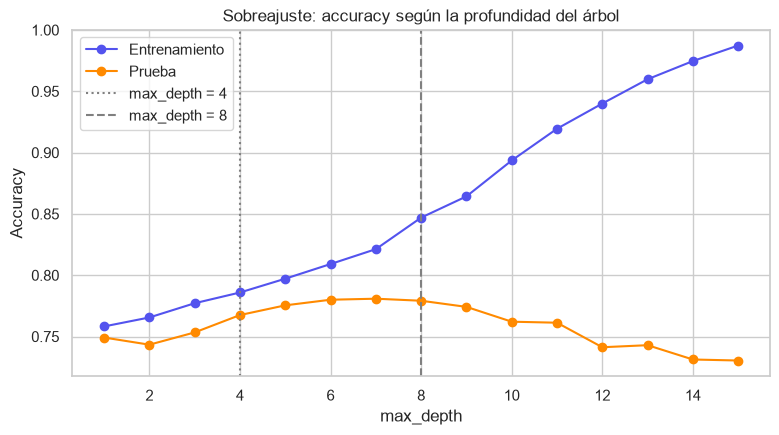

In [36]:
# Curva completa: accuracy en entrenamiento y prueba según la profundidad
prof = range(1, 16)
acc_tr, acc_te = [], []
for d in prof:
    a = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train_d, y_train)
    acc_tr.append(a.score(X_train_d, y_train)); acc_te.append(a.score(X_test_d, y_test))

plt.figure(figsize=(9, 4.5))
plt.plot(prof, acc_tr, marker="o", color=MORADO, label="Entrenamiento")
plt.plot(prof, acc_te, marker="o", color=NARANJA, label="Prueba")
plt.axvline(4, color="gray", linestyle=":", label="max_depth = 4")
plt.axvline(8, color="gray", linestyle="--", label="max_depth = 8")
plt.title("Sobreajuste: accuracy según la profundidad del árbol")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Interpretación
| Configuración | Accuracy train | Accuracy test | Recall test | F1 test | Recall CV | F1 CV |
|---|---|---|---|---|---|---|
| max_depth = 4 | 78,6 % | 76,8 % | 41,6 % | 0,529 | 42,6 % | 0,539 |
| max_depth = 8 | 84,7 % | 77,9 % | 51,3 % | 0,593 | 48,9 % | 0,568 |

- Con profundidad 4 el árbol es demasiado simple: casi no hay brecha entre entrenamiento y prueba (1,8 puntos), pero solo detecta 4 de cada 10 pedidos tarde (recall 41,6 %).
- Con profundidad 8 mejora en recall y F1 tanto en la prueba como en la validación cruzada. La brecha entre entrenamiento y prueba crece a 6,8 puntos: hay algo de sobreajuste, pero moderado.
- La curva muestra que el entrenamiento sube sin parar hasta casi 99 %, mientras que la prueba llega a su mejor punto alrededor de las profundidades 6 y 7 (~78 %) y después baja. Más allá de 8, el árbol empieza a memorizar.

Elegimos max_depth = 8. Detecta más pedidos tarde (objetivo de la Fase 1) y tiene el mejor F1, con un sobreajuste que consideramos aceptable. La profundidad 4 se queda corta en recall.

### 4.2.3 ¿Qué aprendió el árbol? Primeras divisiones e importancia de las variables

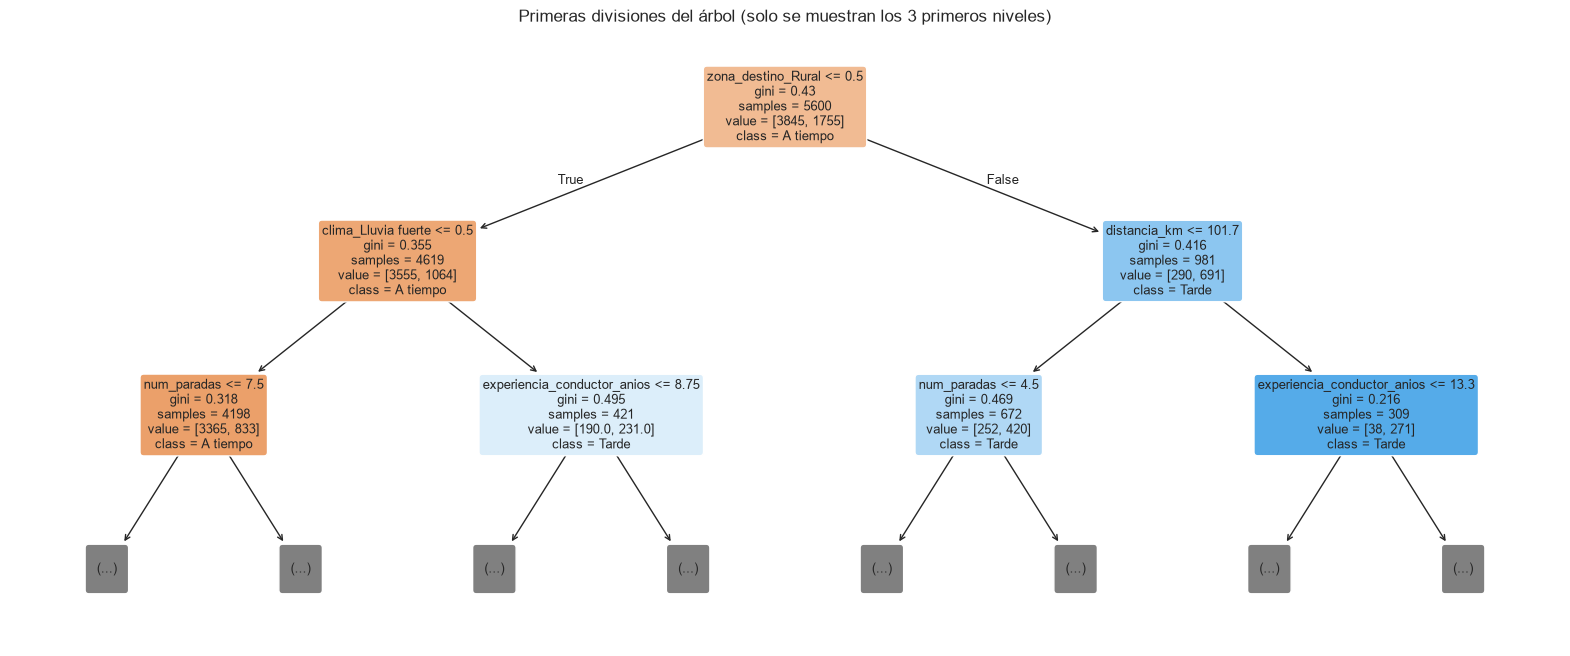

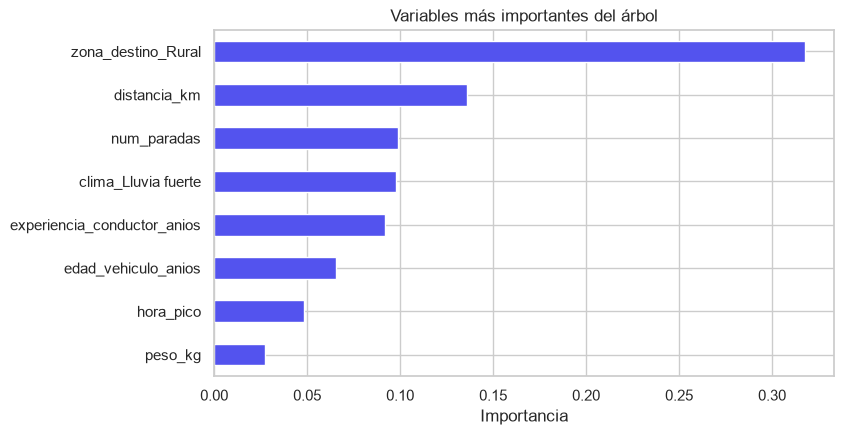

Importancia de hora_salida: 0.008 | de hora_pico: 0.048


In [37]:
arbol_elegido = arbol_8

plt.figure(figsize=(20, 8))
plot_tree(arbol_elegido, max_depth=2, feature_names=list(X_train_d.columns), class_names=["A tiempo", "Tarde"],
          filled=True, rounded=True, fontsize=9, proportion=False)
plt.title("Primeras divisiones del árbol (solo se muestran los 3 primeros niveles)")
plt.show()

imp = pd.Series(arbol_elegido.feature_importances_, index=X_train_d.columns).sort_values().tail(8)
plt.figure(figsize=(8, 4.5))
imp.plot(kind="barh", color=MORADO)
plt.title("Variables más importantes del árbol")
plt.xlabel("Importancia")
plt.show()

print("Importancia de hora_salida:", round(pd.Series(arbol_elegido.feature_importances_, index=X_train_d.columns)["hora_salida"], 3),
      "| de hora_pico:", round(pd.Series(arbol_elegido.feature_importances_, index=X_train_d.columns)["hora_pico"], 3))

### Interpretación
- Primera división (raíz): zona_destino_Rural. Es la pregunta que más separa a los pedidos, y coincide con el EDA (69 % de retraso en rural contra 19 % en urbana).
- Por la rama "no rural": el árbol pregunta enseguida si hay lluvia fuerte. Si no la hay, mira el número de paradas (corte en 7,5): con pocas paradas pregunta por la hora pico y con muchas por la distancia (corte ≈ 29 km). Si hay lluvia fuerte, mira la experiencia del conductor (corte ≈ 8,8 años).
- Por la rama "rural": pregunta si la distancia pasa de ~102 km. Si no pasa, mira el número de paradas (corte en 4,5); si pasa, mira la experiencia del conductor (corte ≈ 13 años).
- Variables más importantes: zona rural (0,32), distancia (0,14), número de paradas (0,10), lluvia fuerte (0,10) y experiencia del conductor (0,09). Es el mismo grupo de factores que vimos en el EDA.
- Sobre la hora: el árbol le da más importancia a hora_pico (0,048) que a hora_salida (0,008). Un árbol puede capturar la no linealidad con varios cortes, pero la variable hora_pico se lo resume en una sola pregunta.

## 4.3 Modelo 2: Regresión logística

### 4.3.1 Dos configuraciones: class_weight = None y class_weight = balanced
Con balanced, el modelo le da más peso a los errores de la clase minoritaria (tarde), lo que empuja el recall hacia arriba. Usamos los datos escalados.

In [38]:
log_normal = evaluar("Regresión logística", "class_weight = None", LogisticRegression(max_iter=1000, random_state=SEED),
                     X_train_esc, y_train, X_test_esc, y_test)
log_balanced = evaluar("Regresión logística", "class_weight = 'balanced'", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
                       X_train_esc, y_train, X_test_esc, y_test)

tabla_log = pd.DataFrame([r for r in resultados if r["Modelo"] == "Regresión logística"]).set_index("Configuración").drop(columns="Modelo")
tabla_log.round(3)

,Accuracy train,Accuracy test,Precision test,Recall test,F1 test,Recall CV,F1 CV
Configuración,,,,,,,
class_weight = None,0.827,0.816,0.748,0.621,0.679,0.623,0.689
class_weight = 'balanced',0.799,0.793,0.639,0.781,0.703,0.779,0.705


### Interpretación
| Configuración | Accuracy train | Accuracy test | Precision test | Recall test | F1 test | Recall CV | F1 CV |
|---|---|---|---|---|---|---|---|
| class_weight = None | 82,7 % | 81,6 % | 74,8 % | 62,1 % | 0,679 | 62,3 % | 0,689 |
| class_weight = balanced | 79,9 % | 79,3 % | 63,9 % | 78,1 % | 0,703 | 77,9 % | 0,705 |

- No hay sobreajuste: en las dos configuraciones, entrenamiento y prueba están a menos de 1,5 puntos, y la validación cruzada da casi lo mismo que la prueba. El modelo es estable.
- balanced sube el recall de 62 % a 78 %: detecta aproximadamente 8 de cada 10 pedidos que llegan tarde. A cambio, la precision baja de 75 % a 64 % y el accuracy baja 2,3 puntos. El F1 también mejora (0,679 a 0,703).

Elegimos class_weight = balanced. En la Fase 1 dijimos que dejar pasar un retraso (falso negativo) cuesta más que una falsa alarma, y esta configuración detecta bastante más retrasos sin empeorar el F1. Aceptamos perder algo de accuracy y de precision.

### 4.3.2 ¿Qué aprendió la regresión logística? Signo de los coeficientes
Como las variables están escaladas, cada coeficiente muestra el efecto de subir una desviación estándar (en las numéricas) o de la desviación estándar de la dummy (en las dummies, que también escalamos). Positivo = aumenta el riesgo de llegar tarde; negativo = lo reduce. Estos coeficientes escalados sirven para comparar qué variables pesan más; para leer el efecto real de una categoría (por ejemplo, "lluvia fuerte frente a soleado") los convertimos a unidades reales en la sección 4.3.3.

Aumentan el riesgo de llegar tarde (coeficiente > 0,10):
distancia_km                  0.94
clima_Lluvia fuerte           0.79
num_paradas                   0.59
hora_pico                     0.58
edad_vehiculo_anios           0.57
zona_destino_Rural            0.52
clima_Lluvia                  0.47
prioridad_Express             0.42
centro_distribucion_Bogotá    0.34
tipo_vehiculo_Furgón          0.33
tipo_vehiculo_Camión          0.25
dia_semana_Sábado             0.24
dia_semana_Viernes            0.22
clima_Sin dato                0.18

Reducen el riesgo (coeficiente < -0,10):
experiencia_conductor_anios   -0.68

Casi sin efecto (entre -0,10 y 0,10): ['peso_kg', 'hora_salida', 'valor_pedido_COP', 'zona_destino_Periurbana', 'clima_Nublado', 'centro_distribucion_Medellín', 'centro_distribucion_Barranquilla', 'tipo_cliente_Empresa', 'tipo_cliente_Tienda', 'dia_semana_Martes', 'dia_semana_Miércoles', 'dia_semana_Jueves', 'dia_semana_Domingo']


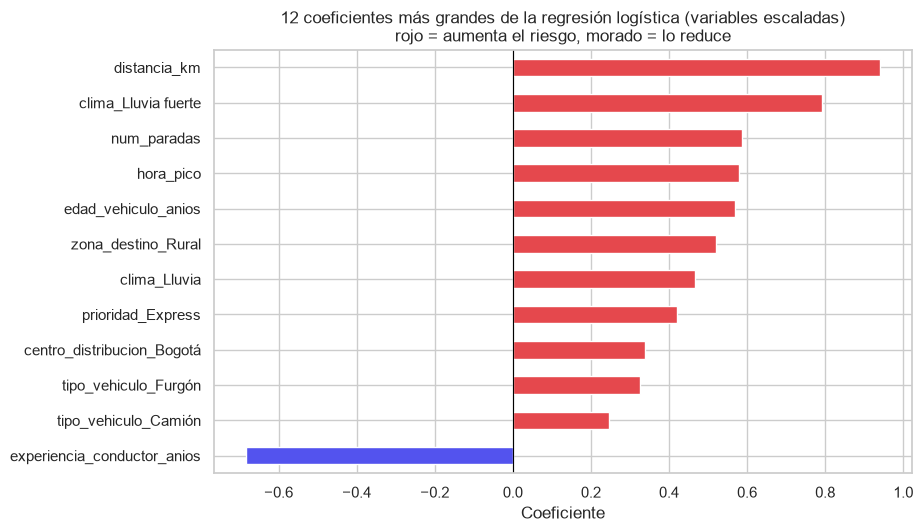


Coeficiente de hora_salida: 0.02 | de hora_pico: 0.58
Multiplicador de odds por +1 desviación en distancia_km: 2.56


In [ ]:
logistica_elegida = log_balanced

coef = pd.Series(logistica_elegida.coef_[0], index=X_train_esc.columns)
print("Aumentan el riesgo de llegar tarde (coeficiente > 0,10):")
print(coef[coef > 0.10].sort_values(ascending=False).round(2).to_string())
print()
print("Reducen el riesgo (coeficiente < -0,10):")
print(coef[coef < -0.10].sort_values().round(2).to_string())
print()
print("Casi sin efecto (entre -0,10 y 0,10):", list(coef[coef.abs() <= 0.10].index))

top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).sort_values()
plt.figure(figsize=(9, 5.5))
top.plot(kind="barh", color=[MORADO if v < 0 else ROJO for v in top])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("12 coeficientes más grandes de la regresión logística (variables escaladas)\nrojo = aumenta el riesgo, morado = lo reduce")
plt.xlabel("Coeficiente")
plt.show()

print()
print("Coeficiente de hora_salida:", round(coef["hora_salida"], 2), "| de hora_pico:", round(coef["hora_pico"], 2))
print("Multiplicador de odds por +1 desviación en distancia_km:", round(float(np.exp(coef["distancia_km"])), 2))

In [49]:
# Traducción a unidades reales: coeficiente escalado / desviación estándar de la variable
desv = pd.Series(escalador.scale_, index=X_train_esc.columns)
efecto_real = coef / desv                 # coeficiente por unidad original (km, paradas, años, o "sí/no" en las dummies)
multiplicador = np.exp(efecto_real)       # cuánto se multiplican los odds de llegar tarde

columnas_num = ["distancia_km", "peso_kg", "num_paradas", "hora_salida",
                "experiencia_conductor_anios", "edad_vehiculo_anios", "valor_pedido_COP"]

print("Variables numéricas: multiplicador de los odds al subir una cantidad")
unidades = [("distancia_km", "+10 km", 10), ("num_paradas", "+1 parada", 1),
            ("experiencia_conductor_anios", "+1 año de experiencia", 1), ("edad_vehiculo_anios", "+1 año de antigüedad", 1)]
for var, texto, k in unidades:
    print(f"  {var:30s} {texto:24s} -> x {np.exp(efecto_real[var] * k):.2f}")

print()
print("Categorías (sí/no) frente a su categoría de referencia: multiplicador de los odds")
odds_cat = multiplicador.drop(columnas_num).sort_values(ascending=False).round(2)
print(odds_cat.to_string())

Variables numéricas: multiplicador de los odds al subir una cantidad
  distancia_km                   +10 km                   -> x 1.31
  num_paradas                    +1 parada                -> x 1.20
  experiencia_conductor_anios    +1 año de experiencia    -> x 0.81
  edad_vehiculo_anios            +1 año de antigüedad     -> x 1.14

Categorías (sí/no) frente a su categoría de referencia: multiplicador de los odds
clima_Lluvia fuerte                 14.98
zona_destino_Rural                   3.92
hora_pico                            3.37
clima_Lluvia                         3.19
prioridad_Express                    2.65
centro_distribucion_Bogotá           2.08
dia_semana_Sábado                    2.00
tipo_vehiculo_Furgón                 1.92
dia_semana_Viernes                   1.89
clima_Sin dato                       1.88
tipo_vehiculo_Camión                 1.85
clima_Nublado                        1.23
dia_semana_Martes                    1.19
zona_destino_Periurbana       

### Interpretación
Cómo leer los multiplicadores de la tabla de arriba: significa que los odds de llegar tarde (la razón entre la probabilidad de llegar tarde y la de llegar a tiempo) se duplican, manteniendo las demás variables iguales. Mayor que 1 aumenta el riesgo; menor que 1 lo reduce. El gráfico de coeficientes escalados sirve para comparar qué variables pesan más, y la tabla para entender el efecto en unidades de negocio.

Aumentan el riesgo (multiplicador mayor que 1):
- clima: frente a un día soleado, la lluvia fuerte multiplica los odds por 14,98 y la lluvia por 3,19; el nublado casi no cambia nada (×1,23).
- zona_destino_Rural: ×3,92 frente a la zona urbana.
- hora_pico: ×3,37 frente a salir fuera de hora pico.
- prioridad_Express: ×2,65 frente a Normal.
- centro_distribucion_Bogotá: ×2,08 frente a Cali.
- tipo_vehiculo: furgón ×1,92 y camión ×1,85 frente a la moto.
- dia_semana: sábado ×2,00 y viernes ×1,89 frente al lunes.
- distancia_km: cada 10 km más multiplica los odds por 1,31. Con el coeficiente escalado (+0,94) es la variable numérica que más pesa: una desviación estándar son unos 35 km y multiplica los odds por 2,56.
- num_paradas: cada parada más, ×1,20. edad_vehiculo_anios: cada año más de antigüedad, ×1,14.

Reducen el riesgo (multiplicador menor que 1): experiencia_conductor_anios. Cada año más de experiencia multiplica los odds por 0,81, es decir, los reduce cerca de un 19 %. Es la única variable con un efecto claramente negativo.

Casi sin efecto: peso_kg y valor_pedido_COP (están en la lista de "casi sin efecto" de la celda anterior), tipo_cliente (Empresa ×0,99 y Tienda ×1,09), Medellín y Barranquilla frente a Cali (×0,93 y ×1,03), el domingo (×0,96) y, en menor medida, nublado, periurbana, martes, miércoles y jueves (entre ×1,08 y ×1,23). Es consistente con el EDA, donde el tipo de cliente y el valor del pedido no cambiaban el riesgo. La categoría clima_Sin dato (×1,88) queda entre el nublado y la lluvia: el modelo trata a los pedidos sin dato de clima como un caso intermedio, lo esperable para un clima desconocido.

Sobre la hora: el coeficiente de hora_salida es casi cero (+0,02), pero el de hora_pico es +0,58 (×3,37). Una logística, que usa una relación lineal, no ve el efecto de la hora en la variable original; solo lo captura gracias a la variable que creamos. El árbol, en cambio, puede hacer cortes por tramos.

Estos coeficientes miden asociaciones, no causas.

## 4.4 Resumen de la Fase 4

In [42]:
resumen_fase4 = pd.DataFrame(resultados).set_index(["Modelo", "Configuración"])
resumen_fase4.round(3)

Accuracy train  Accuracy test  \
Modelo              Configuración                                              
Árbol de decisión   max_depth = 4                       0.786          0.768   
                    max_depth = 8                       0.847          0.779   
Regresión logística class_weight = None                 0.827          0.816   
                    class_weight = 'balanced'           0.799          0.793   

                                               Precision test  Recall test  \
Modelo              Configuración                                            
Árbol de decisión   max_depth = 4                       0.725        0.416   
                    max_depth = 8                       0.702        0.513   
Regresión logística class_weight = None                 0.748        0.621   
                    class_weight = 'balanced'           0.639        0.781   

                                               F1 test  Recall CV  F1 CV  
Modelo              Configuración                                         
Árbol de decisión   max_depth = 4                0.529      0.426  0.539  
                    max_depth = 8                0.593      0.489  0.568  
Regresión logística class_weight = None          0.679      0.623  0.689  
                    class_weight = 'balanced'    0.703      0.779  0.705

### Interpretación
| Modelo | Configuración elegida | Por qué |
|---|---|---|
| Árbol de decisión | max_depth = 8 | Mejor recall y F1 que con profundidad 4, con un sobreajuste moderado (la prueba baja después de 6-7 niveles). |
| Regresión logística | class_weight = balanced | Detecta ~78 % de los pedidos tarde (contra 62 %) y tiene el mejor F1, sin sobreajuste. |

Con las configuraciones elegidas, la regresión logística supera al árbol en todas las métricas que priorizamos (recall y F1). La comparación formal de los dos modelos (matrices de confusión, precision, recall, F1 y análisis de sobreajuste) y la elección del modelo para el negocio la hacemos en la Fase 5.

---
# FASE 5 · Evaluación

En la Fase 4 quedaron dos modelos elegidos: el árbol de decisión con max_depth = 8 y la regresión logística con class_weight = balanced. Ahora los evaluamos de forma completa sobre el conjunto de prueba: 2.400 pedidos que los modelos no vieron al entrenar, de los cuales 752 llegaron tarde de verdad.

Lo que hacemos, siguiendo lo que definimos en la Fase 1:

1. Matriz de confusión de cada modelo.
2. Accuracy, precision, recall y F1 en entrenamiento y en prueba, para detectar sobreajuste.
3. Tabla comparativa de los dos modelos, con una línea base: el modelo "tonto" que siempre dice "a tiempo".
4. Elección del mejor modelo para el negocio.

## 5.1 Matriz de confusión (conjunto de prueba)

Cómo se lee: las filas son lo que pasó de verdad y las columnas lo que dijo el modelo. La clase positiva es "Tarde".

- Arriba a la izquierda: pedidos a tiempo que el modelo dijo a tiempo (verdadero negativo, acierto).
- Arriba a la derecha: pedidos a tiempo que el modelo marcó como tarde (falso positivo, falsa alarma).
- Abajo a la izquierda: pedidos tarde que el modelo dijo a tiempo (falso negativo, el retraso que se escapa).
- Abajo a la derecha: pedidos tarde que el modelo detectó (verdadero positivo, acierto).

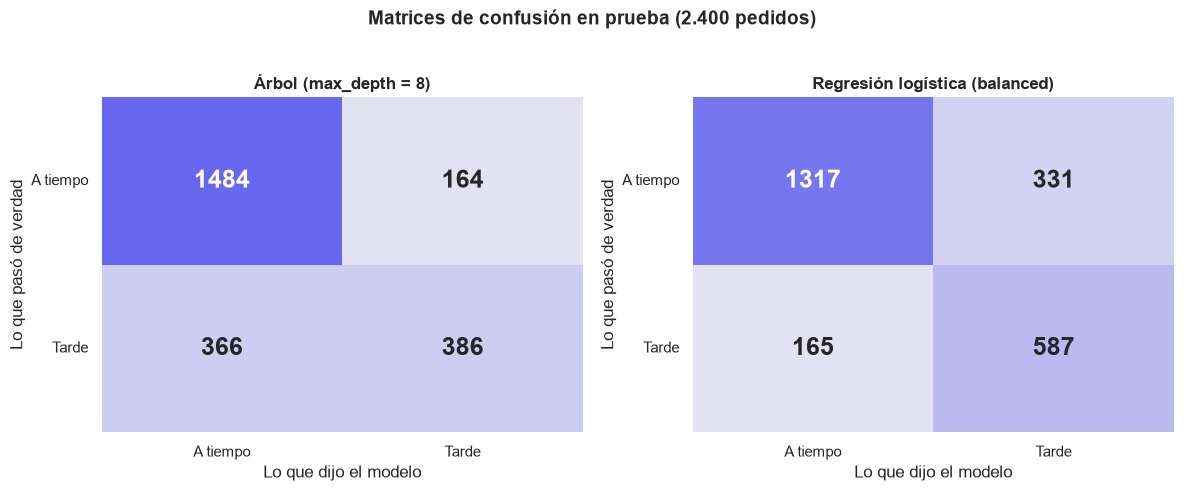

,Árbol (max_depth = 8),Regresión logística (balanced)
Retrasos detectados (verdaderos positivos),386,587
Retrasos que se escapan (falsos negativos),366,165
Falsas alarmas (falsos positivos),164,331
A tiempo y bien clasificados (verdaderos negativos),1484,1317


Pedidos de prueba: 2400 | llegaron tarde de verdad: 752


In [43]:
from sklearn.metrics import confusion_matrix

# Los dos modelos elegidos en la Fase 4, con los datos que usa cada uno
modelos = {
    "Árbol (max_depth = 8)":          (arbol_elegido,     X_train_d,   X_test_d),
    "Regresión logística (balanced)": (logistica_elegida, X_train_esc, X_test_esc),
}

conteos = {}      # aquí guardamos VN, FP, FN y VP de cada modelo
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (nombre, (modelo, Xtr, Xte)) in zip(ejes, modelos.items()):
    pred = modelo.predict(Xte)
    cm = confusion_matrix(y_test, pred)                  # filas = real, columnas = predicho
    vn, fp, fn, vp = cm.ravel()
    conteos[nombre] = {"vn": vn, "fp": fp, "fn": fn, "vp": vp}
    sns.heatmap(cm, annot=True, fmt="d", cmap=sns.light_palette(MORADO, as_cmap=True), cbar=False, ax=ax, vmin=0, vmax=1700,
                annot_kws={"size": 18, "fontweight": "bold"},
                xticklabels=["A tiempo", "Tarde"], yticklabels=["A tiempo", "Tarde"])
    ax.set_yticklabels(["A tiempo", "Tarde"], rotation=0)
    ax.set_title(nombre, fontsize=12, fontweight="bold")
    ax.set_xlabel("Lo que dijo el modelo")
    ax.set_ylabel("Lo que pasó de verdad")
plt.suptitle("Matrices de confusión en prueba (2.400 pedidos)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

tabla_conteos = pd.DataFrame({
    nombre: {"Retrasos detectados (verdaderos positivos)": c["vp"],
             "Retrasos que se escapan (falsos negativos)": c["fn"],
             "Falsas alarmas (falsos positivos)": c["fp"],
             "A tiempo y bien clasificados (verdaderos negativos)": c["vn"]}
    for nombre, c in conteos.items()
})
display(tabla_conteos)
print("Pedidos de prueba:", len(y_test), "| llegaron tarde de verdad:", int(y_test.sum()))

### Interpretación
De los 2.400 pedidos de prueba, 752 llegaron tarde y 1.648 a tiempo. Esto fue lo que hizo cada modelo:

| | Árbol (max_depth = 8) | Regresión logística (balanced) |
|---|---|---|
| Retrasos detectados (verdaderos positivos) | 386 | 587 |
| Retrasos que se escapan (falsos negativos) | 366 | 165 |
| Falsas alarmas (falsos positivos) | 164 | 331 |
| A tiempo bien clasificados (verdaderos negativos) | 1.484 | 1.317 |

- El árbol deja pasar 366 de los 752 retrasos, casi la mitad. Tiene pocas falsas alarmas (164), pero se le escapan demasiados retrasos.
- La regresión logística detecta 587 retrasos y solo deja pasar 165. A cambio genera 331 falsas alarmas, el doble que el árbol.
- Según la Fase 1, un retraso que se escapa (falso negativo) es más costoso que una falsa alarma. Mirando solo las matrices, la logística es la que más se acerca a lo que necesita TransAndes.

## 5.2 Accuracy, precision, recall y F1: entrenamiento contra prueba

Para detectar el sobreajuste calculamos las cuatro métricas en los dos conjuntos. Si un modelo es mucho mejor en entrenamiento que en prueba, memorizó en lugar de aprender.

Entrenamiento  Prueba  \
Modelo                         Métrica                            
Árbol (max_depth = 8)          Accuracy           0.847   0.779   
                               Precision          0.851   0.702   
                               Recall             0.621   0.513   
                               F1                 0.718   0.593   
Regresión logística (balanced) Accuracy           0.799   0.793   
                               Precision          0.649   0.639   
                               Recall             0.785   0.781   
                               F1                 0.710   0.703   

                                          Diferencia (train - test)  
Modelo                         Métrica                               
Árbol (max_depth = 8)          Accuracy                       0.068  
                               Precision                      0.149  
                               Recall                         0.107  
                               F1                             0.125  
Regresión logística (balanced) Accuracy                       0.006  
                               Precision                      0.009  
                               Recall                         0.004  
                               F1                             0.007

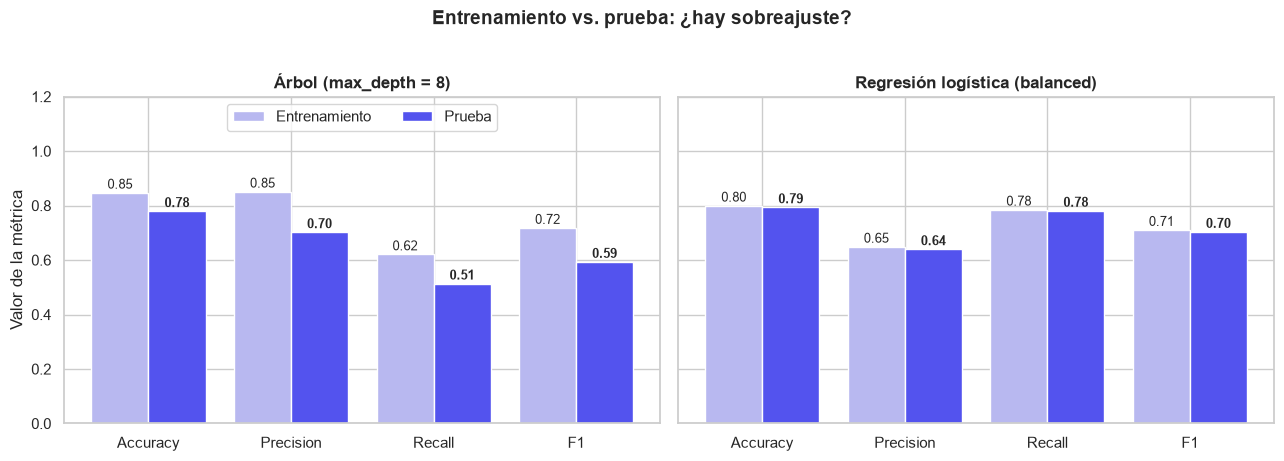

In [44]:
def metricas(y_real, y_pred):
    """Las cuatro métricas de la clase 'tarde'."""
    return {"Accuracy":  accuracy_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred, zero_division=0),
            "Recall":    recall_score(y_real, y_pred, zero_division=0),
            "F1":        f1_score(y_real, y_pred, zero_division=0)}

filas = []
for nombre, (modelo, Xtr, Xte) in modelos.items():
    m_train = metricas(y_train, modelo.predict(Xtr))
    m_test  = metricas(y_test,  modelo.predict(Xte))
    for m in m_train:
        filas.append({"Modelo": nombre, "Métrica": m, "Entrenamiento": m_train[m], "Prueba": m_test[m],
                      "Diferencia (train - test)": m_train[m] - m_test[m]})
tabla_sobreajuste = pd.DataFrame(filas)
display(tabla_sobreajuste.set_index(["Modelo", "Métrica"]).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, nombre in zip(ejes, modelos):
    t = tabla_sobreajuste[tabla_sobreajuste["Modelo"] == nombre].set_index("Métrica")
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["Entrenamiento"], width=0.4, color=LILA, label="Entrenamiento")
    ax.bar(x + 0.2, t["Prueba"], width=0.4, color=MORADO, label="Prueba")
    for i, (a, b) in enumerate(zip(t["Entrenamiento"], t["Prueba"])):
        ax.text(i - 0.2, a + 0.015, f"{a:.2f}", ha="center", fontsize=9)
        ax.text(i + 0.2, b + 0.015, f"{b:.2f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(t.index)
    ax.set_ylim(0, 1.2)
    ax.set_title(nombre, fontsize=12, fontweight="bold")
ejes[0].set_ylabel("Valor de la métrica")
ejes[0].legend(loc="upper center", ncol=2)
plt.suptitle("Entrenamiento vs. prueba: ¿hay sobreajuste?", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Interpretación
- Árbol de decisión: hay sobreajuste: Todas las métricas bajan de entrenamiento a prueba: accuracy de 0,847 a 0,779 (-0,068), precision de 0,851 a 0,702 (-0,149), recall de 0,621 a 0,513 (-0,107) y F1 de 0,718 a 0,593 (-0,125). El árbol aprendió detalles del entrenamiento que no se repiten en pedidos nuevos. Limitar la profundidad a 8 lo redujo frente al árbol libre, pero no lo eliminó.
- Regresión logística: no hay sobreajuste: Las diferencias son de menos de 1 punto en las cuatro métricas (accuracy -0,006, precision -0,009, recall -0,004, F1 -0,007): rinde casi igual con pedidos nuevos que con los que vio al entrenar.
- Por eso podemos confiar más en la logística: lo que medimos en prueba es lo que esperamos ver cuando se use con pedidos nuevos.

## 5.3 Tabla comparativa de los dos modelos

Comparamos los dos modelos en prueba y los ponemos al lado de la línea base: un modelo "tonto" que dice "a tiempo" para todos los pedidos. Sirve para ver cuánto aporta realmente cada modelo.

,Accuracy,Precision,Recall,F1,Retrasos detectados,Retrasos que se escapan,Falsas alarmas
Línea base: siempre 'a tiempo',0.687,0.000,0.000,0.000,0,752,0
Árbol (max_depth = 8),0.779,0.702,0.513,0.593,386,366,164
Regresión logística (balanced),0.793,0.639,0.781,0.703,587,165,331


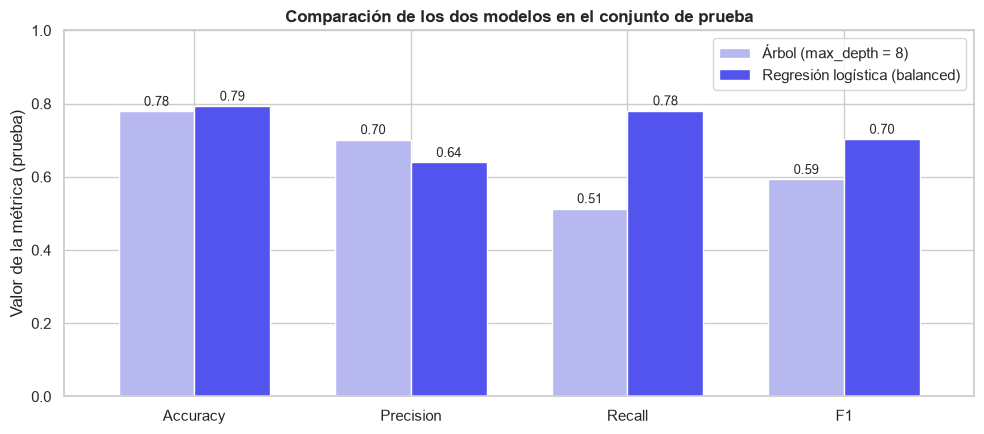

In [45]:
# Línea base: dice "a tiempo" (0) para todos los pedidos
pred_base = np.zeros(len(y_test), dtype=int)
filas = {"Línea base: siempre 'a tiempo'": {**metricas(y_test, pred_base), "Retrasos detectados": 0,
                                           "Retrasos que se escapan": int(y_test.sum()), "Falsas alarmas": 0}}
for nombre, (modelo, Xtr, Xte) in modelos.items():
    c = conteos[nombre]
    filas[nombre] = {**metricas(y_test, modelo.predict(Xte)), "Retrasos detectados": c["vp"],
                     "Retrasos que se escapan": c["fn"], "Falsas alarmas": c["fp"]}
comparacion = pd.DataFrame(filas).T
columnas_conteo = ["Retrasos detectados", "Retrasos que se escapan", "Falsas alarmas"]
comparacion[columnas_conteo] = comparacion[columnas_conteo].astype(int)
display(comparacion.round(3))

# Gráfica: las cuatro métricas de los dos modelos en prueba
graf = comparacion.loc[list(modelos), ["Accuracy", "Precision", "Recall", "F1"]]
ax = graf.T.plot(kind="bar", figsize=(10, 4.5), color=[LILA, MORADO], width=0.7)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, 1)
ax.set_ylabel("Valor de la métrica (prueba)")
ax.set_title("Comparación de los dos modelos en el conjunto de prueba", fontweight="bold")
ax.legend(title="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretación
- Los dos modelos superan en accuracy a la línea base (68,7 %): el árbol llega a 77,9 % y la logística a 79,3 %. Pero la línea base tiene recall 0, no detecta ni un retraso, y por eso el accuracy solo no sirve para elegir.
- Frente al árbol, la logística gana en recall (0,781 contra 0,513), en F1 (0,703 contra 0,593) y también en accuracy (0,793 contra 0,779). El árbol solo la supera en precision (0,702 contra 0,639).
- En pedidos: la logística detecta 201 retrasos más que el árbol (587 contra 386) y a cambio produce 167 falsas alarmas más (331 contra 164). 

## 5.4 ¿Qué modelo elegimos para el negocio?

En la Fase 1 dijimos que el falso negativo (un retraso que se escapa) es más caro que una falsa alarma. Por eso no elegimos por accuracy sino por recall, mirando también precision y F1 para no llenar a operaciones de alertas falsas. Traducimos las métricas a lo que vería operaciones en el día a día:

In [46]:
for nombre, c in conteos.items():
    alertas = c["vp"] + c["fp"]
    tardes = c["vp"] + c["fn"]
    print(nombre)
    print(f"  Marca como riesgo {alertas} de {len(y_test)} pedidos ({alertas / len(y_test) * 100:.0f} %)")
    print(f"  De cada 100 pedidos que de verdad llegan tarde, detecta {c['vp'] / tardes * 100:.0f} y se le escapan {c['fn'] / tardes * 100:.0f}")
    print(f"  De cada 100 alertas, {c['vp'] / alertas * 100:.0f} son retrasos reales y {c['fp'] / alertas * 100:.0f} son falsas alarmas")
    print()

Árbol (max_depth = 8)
  Marca como riesgo 550 de 2400 pedidos (23 %)
  De cada 100 pedidos que de verdad llegan tarde, detecta 51 y se le escapan 49
  De cada 100 alertas, 70 son retrasos reales y 30 son falsas alarmas

Regresión logística (balanced)
  Marca como riesgo 918 de 2400 pedidos (38 %)
  De cada 100 pedidos que de verdad llegan tarde, detecta 78 y se le escapan 22
  De cada 100 alertas, 64 son retrasos reales y 36 son falsas alarmas



### Interpretación y decisión
**Elegimos la regresión logística con class_weight = balanced.** 

1. Detecta mucho más retraso. Detecta 78 de cada 100 pedidos que llegan tarde; el árbol detecta 51. Como el falso negativo es el error más costoso, el recall es la métrica prioritaria.
2. No lo logra a costa de todo lo demás. Tiene el mejor F1 (0,703 contra 0,593) y una precision aceptable: de cada 100 alertas, 64 son retrasos reales.
3. Es estable. No tiene sobreajuste (menos de 1 punto de diferencia entre entrenamiento y prueba en todas las métricas), mientras que el árbol sí.
4. Es interpretable. Sus coeficientes (sección 4.3) muestran qué condiciones aumentan el riesgo, que es la segunda parte de la pregunta de negocio.

**Lo que aceptamos a cambio:** 36 de cada 100 alertas son falsas alarmas y operaciones tendría que revisar el 38 % de los pedidos. En la Fase 1 dijimos que ese costo es pequeño y controlable (una medida preventiva), frente a una penalidad o un cliente perdido.

**Por qué no elegimos por accuracy:** la regresión logística sin balanced tiene el accuracy más alto de todas las configuraciones (81,6 %), pero su recall es 62,1 %: dejaría escapar casi 4 de cada 10 retrasos.

## 5.5  ¿y si operaciones quiere más o menos alertas?

La regresión logística no solo dice "tarde" o "a tiempo": calcula un puntaje de riesgo entre 0 y 1, y por defecto marca como tarde a los pedidos con puntaje de 0,5 o más. Ese punto de corte (el umbral) se puede mover según cuántos pedidos pueda revisar operaciones. Lo probamos como ejercicio; el modelo que evaluamos arriba usa el umbral por defecto (0,5).

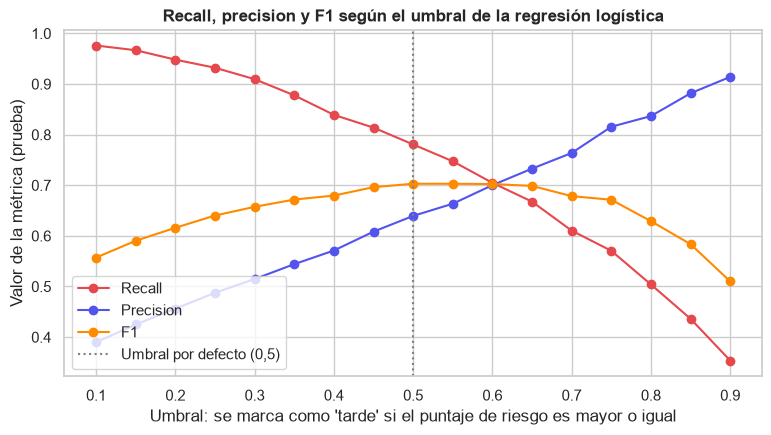

,% de pedidos marcados como riesgo,Recall,Precision,F1
Umbral,,,,
0.3,55.375,0.910,0.515,0.657
0.4,46.042,0.839,0.571,0.680
0.5,38.250,0.781,0.639,0.703
0.6,31.542,0.705,0.700,0.702
0.7,25.042,0.610,0.764,0.678
0.8,18.875,0.504,0.837,0.629


In [47]:
puntaje = logistica_elegida.predict_proba(X_test_esc)[:, 1]      # puntaje de riesgo de cada pedido de prueba

umbrales = np.arange(0.1, 0.91, 0.05)
curva = pd.DataFrame({
    "Umbral": umbrales,
    "Recall":    [recall_score(y_test, (puntaje >= u).astype(int), zero_division=0) for u in umbrales],
    "Precision": [precision_score(y_test, (puntaje >= u).astype(int), zero_division=0) for u in umbrales],
    "F1":        [f1_score(y_test, (puntaje >= u).astype(int), zero_division=0) for u in umbrales],
})
plt.figure(figsize=(9, 4.5))
plt.plot(curva["Umbral"], curva["Recall"], marker="o", color=ROJO, label="Recall")
plt.plot(curva["Umbral"], curva["Precision"], marker="o", color=MORADO, label="Precision")
plt.plot(curva["Umbral"], curva["F1"], marker="o", color=NARANJA, label="F1")
plt.axvline(0.5, color="gray", linestyle=":", label="Umbral por defecto (0,5)")
plt.title("Recall, precision y F1 según el umbral de la regresión logística", fontweight="bold")
plt.xlabel("Umbral: se marca como 'tarde' si el puntaje de riesgo es mayor o igual")
plt.ylabel("Valor de la métrica (prueba)")
plt.legend(loc="lower left")
plt.show()

tabla_umbral = pd.DataFrame({
    "% de pedidos marcados como riesgo": [(puntaje >= u).mean() * 100 for u in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]],
    "Recall":    [recall_score(y_test, (puntaje >= u).astype(int)) for u in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]],
    "Precision": [precision_score(y_test, (puntaje >= u).astype(int)) for u in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]],
    "F1":        [f1_score(y_test, (puntaje >= u).astype(int)) for u in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]],
}, index=pd.Index([0.3, 0.4, 0.5, 0.6, 0.7, 0.8], name="Umbral"))
display(tabla_umbral.round(3))

### Interpretación
- El umbral es una palanca para operaciones. Al subirlo se marcan menos pedidos y hay menos falsas alarmas (sube la precision), pero se escapan más retrasos (baja el recall). Al bajarlo pasa lo contrario.
- Con el umbral por defecto (0,5) se marca el 38 % de los pedidos: recall de 0,781 y precision de 0,639.
- Si operaciones solo puede revisar menos pedidos, con umbral 0,7 marcaría el 25 %: detectaría el 61 % de los retrasos y el 76 % de las alertas serían reales.
- Si prefiere cuidar el recall, con umbral 0,4 marcaría el 46 %: detectaría el 84 % de los retrasos, con 57 % de precision.
- Entre 0,5 y 0,6 el F1 es prácticamente el mismo (0,703 y 0,702).
- Es un ejercicio sobre el conjunto de prueba. Además, el puntaje no es una probabilidad real, porque class_weight = balanced lo desplaza hacia arriba. Para fijar un umbral definitivo habría que usar datos nuevos o un conjunto de validación. Para elegir el modelo dejamos el umbral en 0,5.

## 5.6 Resumen de la Fase 5

| | Árbol (max_depth = 8) | Regresión logística (balanced) |
|---|---|---|
| Accuracy (prueba) | 0,779 | 0,793 |
| Precision (prueba) | 0,702 | 0,639 |
| Recall (prueba) | 0,513 | 0,781 |
| F1 (prueba) | 0,593 | 0,703 |
| ¿Sobreajuste? | Sí (accuracy -0,068, precision -0,149) | No (menos de 1 punto) |
| Retrasos detectados / se escapan | 386 / 366 | 587 / 165 |
| Falsas alarmas | 164 | 331 |

**Modelo elegido: regresión logística con class_weight = balanced.** Detecta 78 de cada 100 retrasos, el 64 % de sus alertas son retrasos reales y no tiene sobreajuste. Con esto respondemos la primera parte de la pregunta de negocio: sí se puede predecir, con lo que sabemos en el despacho, qué pedidos están en riesgo.

---
# FASE 6 · Recomendaciones

Cerramos el proyecto respondiendo la pregunta de negocio con lo que vimos en el EDA (Fase 2) y en los modelos (Fases 4 y 5): qué variables se relacionan más con el retraso, qué puede hacer la gerencia de operaciones con eso y qué límites tiene nuestro análisis.

## 6.1 ¿Qué variables parecen más relacionadas con el retraso?

Empezamos por el árbol de decisión. Como el árbol reparte la importancia entre las dummies de una misma variable (por ejemplo, clima_Lluvia y clima_Lluvia fuerte), las sumamos para ver cuánto pesa cada variable original.

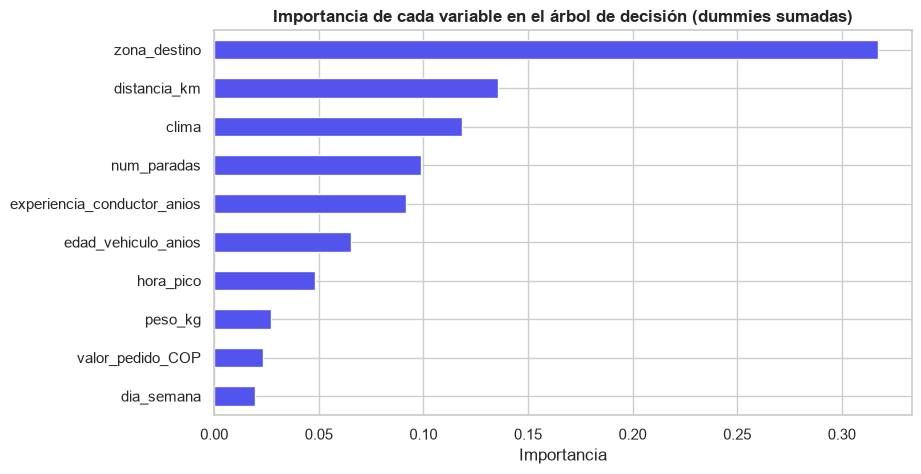

zona_destino                   0.318
distancia_km                   0.136
clima                          0.119
num_paradas                    0.099
experiencia_conductor_anios    0.092
edad_vehiculo_anios            0.065
hora_pico                      0.048
peso_kg                        0.027
valor_pedido_COP               0.023
dia_semana                     0.019


In [48]:
imp_arbol = pd.Series(arbol_elegido.feature_importances_, index=X_train_d.columns)

def variable_original(columna):
    """Junta las dummies con su variable de origen (por ejemplo, clima_Lluvia -> clima)."""
    for var in categorias:
        if columna.startswith(var + "_"):
            return var
    return columna

imp_variable = imp_arbol.groupby(variable_original).sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
imp_variable.head(10).sort_values().plot(kind="barh", color=MORADO)
plt.title("Importancia de cada variable en el árbol de decisión (dummies sumadas)", fontweight="bold")
plt.xlabel("Importancia")
plt.show()

print(imp_variable.head(10).round(3).to_string())

### Interpretación
Juntamos lo que dicen las tres fuentes: el EDA (Fase 2), la importancia en el árbol (gráfico de arriba) y los multiplicadores de la regresión logística (sección 4.3.3).

| Variable | EDA | Árbol (importancia) | Regresión logística |
|---|---|---|---|
| Zona rural | 69 % de retraso (urbana 19 %) | 0,318 (la más importante) | ×3,92 frente a urbana |
| Distancia | correlación 0,42; de 16 % a 67 % de retraso por quintiles | 0,136 | ×1,31 por cada 10 km |
| Lluvia | lluvia fuerte 60 % (soleado 23 %) | 0,119 (clima) | lluvia fuerte ×14,98; lluvia ×3,19 |
| Número de paradas | correlación 0,22 | 0,099 | ×1,20 por parada |
| Experiencia del conductor | correlación -0,18 | 0,092 | ×0,81 por año |
| Antigüedad del vehículo | correlación 0,15 | 0,065 | ×1,14 por año |
| Hora pico | 41,5 % contra 25,6 % | 0,048 | ×3,37 |
| Prioridad Express | 41 % contra 28 % | 0,017 | ×2,65 |
| Centro de Bogotá | 38 % contra 28-29 % | 0,019 (centro) | ×2,08 frente a Cali |
| Viernes y sábado | 35 % y 37 % contra 29 % | 0,019 (día) | ×1,89 y ×2,00 frente al lunes |
| Furgón | 39 % (moto 22 %) | 0,003 (vehículo) | ×1,92 frente a la moto |
| Peso, valor del pedido y tipo de cliente | sin relación (correlaciones 0,02 y -0,01; clientes 31-32 %) | 0,027, 0,023 y 0,007 | casi sin efecto |

- Las tres fuentes coinciden en el grupo principal: zona rural y distancia, lluvia, número de paradas, experiencia del conductor, antigüedad del vehículo y hora pico.
- Zona rural y distancia están muy ligadas (la mediana de distancia es 85,9 km en rural y 11,8 km en urbana, sección 2.3). El árbol usa primero la zona y después la distancia, así que conviene mirarlas juntas.
- Express, Bogotá, los fines de semana y el furgón tienen más retraso en el EDA y en la logística, pero el árbol les da muy poca importancia. Probablemente porque ya usa zona, distancia y clima para dividir. Los tratamos como factores de segundo orden.
- Peso, valor del pedido y tipo de cliente no aportan: las tres fuentes coinciden.

## 6.2 Cómo cambia el riesgo con la experiencia, las paradas y la antigüedad

En el EDA estas tres variables solo las vimos como correlaciones. Para que la gerencia pueda actuar sobre ellas, miramos el % de pedidos tarde por tramos.

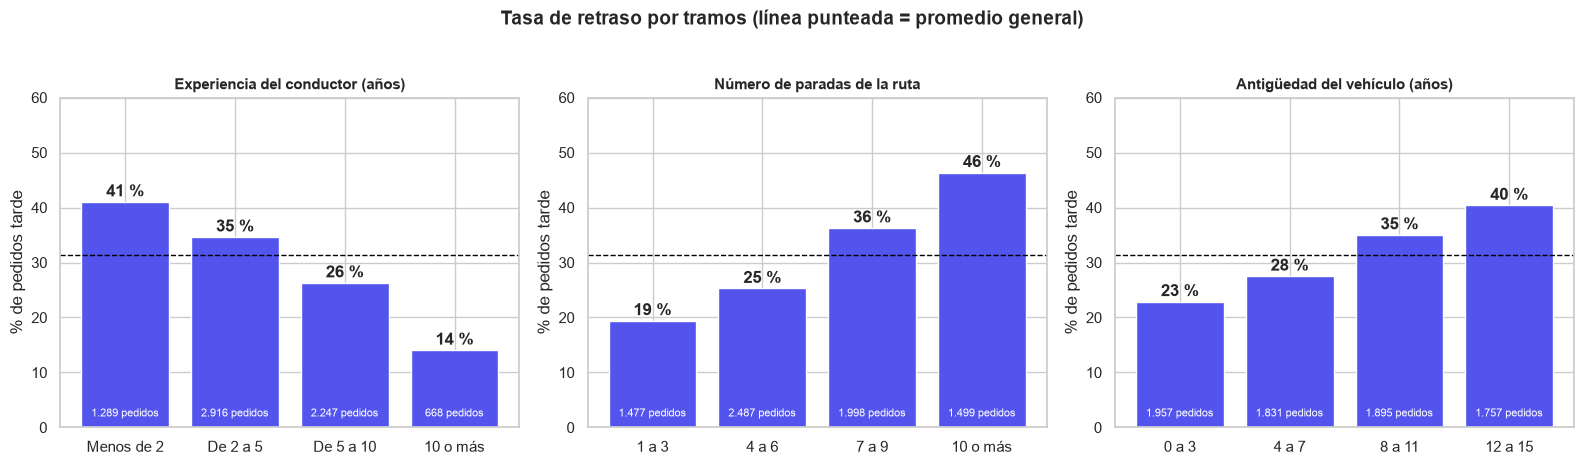

In [49]:
def tasa_por_tramo(variable, cortes, etiquetas, ax, titulo):
    """% de pedidos tarde por tramo de una variable numérica (cada tramo incluye su límite inferior)."""
    tramo = pd.cut(df_eda[variable], bins=cortes, labels=etiquetas, right=False)
    t = df_eda.groupby(tramo, observed=True)["tarde"].agg(["mean", "size"])
    ax.bar(t.index.astype(str), t["mean"] * 100, color=MORADO)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m * 100 + 1, f"{m * 100:.0f} %", ha="center", fontweight="bold")
        ax.text(i, 2, f"{n:,} pedidos".replace(",", "."), ha="center", color="white", fontsize=8)
    ax.axhline(df_eda["tarde"].mean() * 100, color="black", linestyle="--", linewidth=1)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_ylabel("% de pedidos tarde")
    ax.set_ylim(0, 60)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
tasa_por_tramo("experiencia_conductor_anios", [0, 2, 5, 10, np.inf], ["Menos de 2", "De 2 a 5", "De 5 a 10", "10 o más"],
               axes[0], "Experiencia del conductor (años)")
tasa_por_tramo("num_paradas", [1, 4, 7, 10, np.inf], ["1 a 3", "4 a 6", "7 a 9", "10 o más"],
               axes[1], "Número de paradas de la ruta")
tasa_por_tramo("edad_vehiculo_anios", [0, 4, 8, 12, np.inf], ["0 a 3", "4 a 7", "8 a 11", "12 a 15"],
               axes[2], "Antigüedad del vehículo (años)")
plt.suptitle("Tasa de retraso por tramos (línea punteada = promedio general)", y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Interpretación
- Experiencia: el retraso baja de 41 % con conductores de menos de 2 años a 14 % con 10 años o más. Cada tramo es mejor que el anterior.
- Paradas: sube de 19 % en rutas de 1 a 3 paradas a 46 % en rutas de 10 o más.
- Antigüedad del vehículo: sube de 23 % en vehículos de 0 a 3 años a 40 % en los de 12 a 15 años.
- Son tres factores que la empresa sí puede gestionar (a quién asigna, cuántas paradas pone por ruta y cuándo renueva los vehículos), a diferencia del clima o de la zona del cliente.

## 6.3 Los grupos de mayor riesgo

Juntamos los factores que salieron en el EDA y en los modelos y calculamos el % de pedidos tarde en cada grupo (con la base df_eda, sin imputar: los pedidos con el dato faltante no entran en el grupo de esa variable).

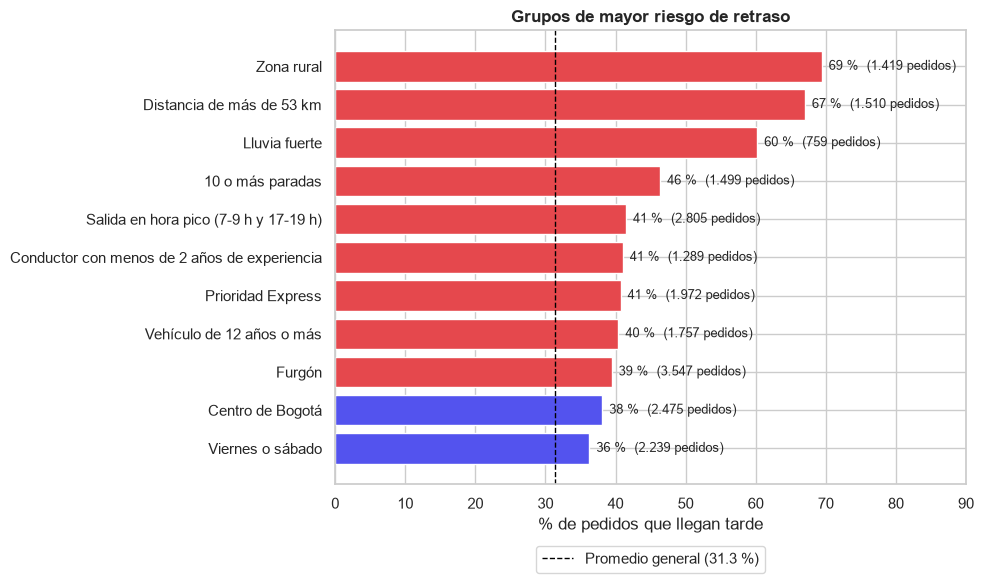

,Pedidos,% tarde
Zona rural,1419,69.4
Distancia de más de 53 km,1510,67.0
Lluvia fuerte,759,60.2
10 o más paradas,1499,46.4
Salida en hora pico (7-9 h y 17-19 h),2805,41.5
Conductor con menos de 2 años de experiencia,1289,41.0
Prioridad Express,1972,40.7
Vehículo de 12 años o más,1757,40.4
Furgón,3547,39.4
Centro de Bogotá,2475,38.1


In [50]:
umbral_dist = df_eda["distancia_km"].quantile(0.8)        # inicio del último quintil de distancia (sección 2.7.2)
en_pico = df_eda["hora_salida"].isin(horas_pico)

segmentos = {
    "Zona rural": df_eda["zona_destino"] == "Rural",
    "Lluvia fuerte": df_eda["clima"] == "Lluvia fuerte",
    f"Distancia de más de {int(umbral_dist)} km": df_eda["distancia_km"] > umbral_dist,
    "10 o más paradas": df_eda["num_paradas"] >= 10,
    "Conductor con menos de 2 años de experiencia": df_eda["experiencia_conductor_anios"] < 2,
    "Salida en hora pico (7-9 h y 17-19 h)": en_pico,
    "Prioridad Express": df_eda["prioridad"] == "Express",
    "Vehículo de 12 años o más": df_eda["edad_vehiculo_anios"] >= 12,
    "Furgón": df_eda["tipo_vehiculo"] == "Furgón",
    "Centro de Bogotá": df_eda["centro_distribucion"] == "Bogotá",
    "Viernes o sábado": df_eda["dia_semana"].isin(["Viernes", "Sábado"]),
}
tabla_seg = pd.DataFrame({
    "Pedidos": {k: int(m.sum()) for k, m in segmentos.items()},
    "% tarde": {k: df_eda.loc[m, "tarde"].mean() * 100 for k, m in segmentos.items()},
}).sort_values("% tarde")

tasa_media = df_eda["tarde"].mean() * 100
plt.figure(figsize=(10, 6))
plt.barh(tabla_seg.index, tabla_seg["% tarde"], color=[ROJO if v > tasa_media * 1.25 else MORADO for v in tabla_seg["% tarde"]])
for i, (v, n) in enumerate(zip(tabla_seg["% tarde"], tabla_seg["Pedidos"])):
    plt.text(v + 1, i, f"{v:.0f} %  ({n:,} pedidos)".replace(",", "."), va="center", fontsize=9)
plt.axvline(tasa_media, color="black", linestyle="--", linewidth=1, label=f"Promedio general ({tasa_media:.1f} %)")
plt.xlim(0, 90)
plt.xlabel("% de pedidos que llegan tarde")
plt.title("Grupos de mayor riesgo de retraso", fontweight="bold")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

display(tabla_seg.sort_values("% tarde", ascending=False).round(1))

### Interpretación
- Los tres grupos de mayor riesgo son la zona rural (69 %), las distancias de más de 53 km (67 %) y la lluvia fuerte (60 %): llegan tarde entre 1,9 y 2,2 veces más que el promedio (31,3 %).
- Les siguen las rutas de 10 o más paradas (46 %), las salidas en hora pico (41,5 %), los conductores con menos de 2 años de experiencia (41 %), los pedidos Express (41 %), los vehículos de 12 años o más (40 %), el furgón (39 %), el centro de Bogotá (38 %) y los viernes y sábados (36 %).
- Todos los grupos están por encima del promedio, pero el tamaño del grupo también importa: por ejemplo, el furgón (3.547 pedidos) o la hora pico (2.805) afectan a muchos más pedidos que la lluvia fuerte (759).

## 6.4 Cuando se juntan varios factores

Los factores no actúan solos. Contamos cuántos de los cinco factores más fuertes tiene cada pedido (zona rural, lluvia fuerte, distancia larga, hora pico y Express) y miramos cómo sube el retraso.

,Pedidos,% tarde
0 factores,2751,11.4
1 factor,2992,25.6
2 factores,1456,53.2
3 factores,654,79.4
4 o 5 factores,147,91.8


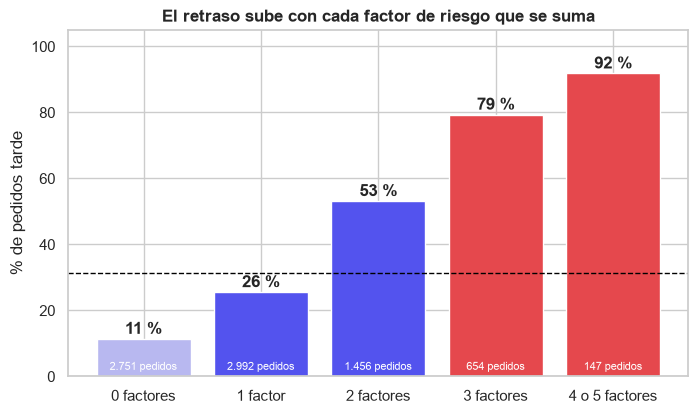

,Pedidos,% tarde
Rural + lluvia fuerte,148,93.2
Rural + hora pico,487,78.9
Rural + Express,367,78.5
Distancia larga + hora pico,523,78.6
Distancia larga + Express,366,77.6


In [51]:
factores = pd.DataFrame({
    "Zona rural": df_eda["zona_destino"] == "Rural",
    "Lluvia fuerte": df_eda["clima"] == "Lluvia fuerte",
    "Distancia larga": df_eda["distancia_km"] > umbral_dist,
    "Hora pico": en_pico,
    "Express": df_eda["prioridad"] == "Express",
})
n_factores = factores.sum(axis=1).clip(upper=4)         # 4 significa "4 o 5 factores"

por_factores = pd.DataFrame({
    "Pedidos": n_factores.value_counts().sort_index(),
    "% tarde": df_eda.groupby(n_factores)["tarde"].mean() * 100,
})
por_factores.index = ["0 factores", "1 factor", "2 factores", "3 factores", "4 o 5 factores"]
display(por_factores.round(1))

plt.figure(figsize=(8, 4.5))
plt.bar(por_factores.index, por_factores["% tarde"], color=[LILA, MORADO, MORADO, ROJO, ROJO])
for i, (v, n) in enumerate(zip(por_factores["% tarde"], por_factores["Pedidos"])):
    plt.text(i, v + 1.5, f"{v:.0f} %", ha="center", fontweight="bold")
    plt.text(i, 2, f"{n:,} pedidos".replace(",", "."), ha="center", color="white", fontsize=8)
plt.axhline(tasa_media, color="black", linestyle="--", linewidth=1)
plt.ylim(0, 105)
plt.ylabel("% de pedidos tarde")
plt.title("El retraso sube con cada factor de riesgo que se suma", fontweight="bold")
plt.show()

# Algunas parejas de factores
parejas = {
    "Rural + lluvia fuerte": factores["Zona rural"] & factores["Lluvia fuerte"],
    "Rural + hora pico": factores["Zona rural"] & factores["Hora pico"],
    "Rural + Express": factores["Zona rural"] & factores["Express"],
    "Distancia larga + hora pico": factores["Distancia larga"] & factores["Hora pico"],
    "Distancia larga + Express": factores["Distancia larga"] & factores["Express"],
}
display(pd.DataFrame({
    "Pedidos": {k: int(m.sum()) for k, m in parejas.items()},
    "% tarde": {k: df_eda.loc[m, "tarde"].mean() * 100 for k, m in parejas.items()},
}).round(1))

### Interpretación
- El retraso sube con cada factor que se suma: 11,4 % sin ningún factor (2.751 pedidos), 25,6 % con uno, 53,2 % con dos, 79,4 % con tres y 91,8 % con cuatro o cinco (147 pedidos).
- Algunas parejas son especialmente malas: rural con lluvia fuerte llega tarde 93,2 % de las veces (148 pedidos). Rural con hora pico (78,9 %), rural con Express (78,5 %), distancia larga con hora pico (78,6 %) y distancia larga con Express (77,6 %) rondan el 78 %.


## 6.5 Recomendaciones para la gerencia de operaciones logísticas

Sugerimos empezar con un piloto (por ejemplo, en un centro de distribución) y comparar los indicadores antes y después.

| # | Recomendación | Qué datos la respaldan | Cómo medir si funciona |
|---|---|---|---|
| 1 | Usar el modelo como semáforo de riesgo en el despacho. Antes de que salga cada pedido, calcular su puntaje de riesgo y revisar los marcados (cambiar vehículo o conductor, adelantar la salida, avisar al cliente). | La regresión logística detecta 78 de cada 100 retrasos y el 64 % de sus alertas son reales (sección 5.4). Con el umbral por defecto se revisa el 38 % de los pedidos; con umbral 0,7 se revisaría el 25 % y se detectaría el 61 % de los retrasos (sección 5.5). | % de retraso entre pedidos marcados y no marcados; recall mes a mes. |
| 2 | Ajustar la promesa de entrega en zonas rurales y rutas largas. Prometer ventanas más amplias, o asignar los mejores recursos, a destinos rurales y rutas de más de 53 km. | Rural: 69 % de retraso (urbana 19 %). Más de 53 km: 67 %. Son los grupos de mayor riesgo y la zona rural es la primera división del árbol (secciones 4.2.3 y 6.3). | % de retraso en rural y en rutas largas. |
| 3 | Protocolo para lluvia fuerte. Consultar el pronóstico al despachar y, si hay lluvia fuerte, reprogramar salidas, reforzar la ruta o avisar al cliente. | Con lluvia fuerte el retraso es 60 % contra 23 % con sol, y es el mayor efecto de la regresión logística (×14,98 en odds). Rural con lluvia fuerte: 93,2 % (148 pedidos). | % de retraso en días de lluvia fuerte. |
| 4 | No juntar factores de riesgo. Evitar sacar rutas rurales o largas en hora pico (7-9 h y 17-19 h) y revisar la promesa Express en rutas de alto riesgo. | Hora pico: 41,5 % contra 25,6 % fuera de pico. Express: 41 % contra 28 %. Rural con hora pico 78,9 %, rural con Express 78,5 %, distancia larga con hora pico 78,6 %. Con tres factores el retraso es 79,4 %. | % de retraso en salidas de hora pico y en pedidos Express. |
| 5 | Asignar conductores y vehículos según el riesgo de la ruta. Dar las rutas largas o rurales a conductores con más experiencia, limitar las paradas por ruta y mantener o renovar los vehículos más viejos. | Experiencia: de 41 % (menos de 2 años) a 14 % (10 años o más). Paradas: de 19 % (1 a 3) a 46 % (10 o más). Vehículos de 12 a 15 años: 40 % contra 23 % en los de 0 a 3 años (sección 6.2). | % de retraso por tramo de experiencia, de paradas y de antigüedad. |
| 6 | Investigar el centro de Bogotá y los viernes y sábados. Revisar qué pasa allí (capacidad, tráfico, turnos). | Bogotá: 38 % contra 28-29 % en los otros centros, con la misma mezcla de zonas y clima. Viernes 35 % y sábado 37 % contra 29 % de lunes a jueves. | El mismo indicador antes y después de intervenir. |

## 6.6 Limitaciones de nuestro análisis

- Asociación, no causalidad: Lo que encontramos (por ejemplo, lluvia fuerte y retraso) son asociaciones: los datos no prueban que una cosa cause la otra. Por eso recomendamos un piloto.
- Un solo año y división al azar: Los datos son de 2025 y dividimos los pedidos al azar en entrenamiento y prueba. En la práctica el modelo se usaría con pedidos futuros, y no probamos qué pasa si cambian las condiciones (otros meses, nuevas rutas).
- Qué se sabe al despachar: Usamos el clima y las paradas registrados en cada despacho. Si el clima real de la ruta solo se conoce después de salir, en la práctica habría que usar un pronóstico, y el desempeño podría ser menor.
- Nulos y valores sospechosos: Imputamos con la mediana global (no por vehículo o zona) y dejamos sin modificar los valores sospechosos (distancias de más de 200 km, motos con más de 100 kg). Eso puede haber introducido algo de error.
- Pocos modelos y pocos hiperparámetros: Probamos dos modelos y dos configuraciones de cada uno; otro árbol, KNN o un modelo más complejo podrían rendir mejor. Además, elegimos max_depth y class_weight mirando también el conjunto de prueba (apoyados con validación cruzada), así que las métricas de prueba pueden ser algo optimistas.
- Lo que el modelo no ve: La regresión logística suma efectos y no modela interacciones: no comprobamos si, por ejemplo, rural y lluvia fuerte juntos empeoran más que la suma de sus efectos. Tampoco medimos el costo en pesos de cada tipo de error, y el modelo aún deja escapar 22 de cada 100 retrasos y genera 36 falsas alarmas por cada 100 alertas.


## 6.7 Conclusión: respuesta a la pregunta de negocio

**¿Podemos predecir si un pedido llegará tarde con la información del despacho?** Sí, con límites. La regresión logística (class_weight = balanced) detecta 78 de cada 100 pedidos que llegan tarde y 64 de cada 100 alertas son retrasos reales. Es mucho mejor que no hacer nada (la línea base no detecta ninguno), pero no es perfecta: se le escapan 22 de cada 100 retrasos y genera falsas alarmas.

**¿Qué condiciones aumentan el riesgo?** Las más fuertes son la zona rural y las distancias largas (más de 53 km), la lluvia fuerte, la hora pico, las rutas con muchas paradas, los conductores con poca experiencia, los vehículos viejos y la prioridad Express. Cuando se juntan varios factores el retraso se vuelve muy probable (79,4 % con tres). El tipo de cliente, el valor y el peso del pedido casi no influyen.

---
# Declaración de uso de IA

Usamos Claude  como herramienta de apoyo durante el proyecto, dentro del nivel 3 permitido por la profesora. Lo usamos para:

- Armar la estructura del notebook siguiendo las fases de CRISP-DM y el estilo del laboratorio de EDA visto en clase.
- Escribir y corregir código: limpieza de datos, gráficas, preparación de los datos, entrenamiento de los modelos y cálculo de las métricas, incluidos los errores de ejecución que fueron apareciendo.

Las decisiones del análisis (cómo tratar los valores imposibles, la estrategia de imputación de cada columna, los hiperparámetros que probamos, el modelo que elegimos para el negocio y las recomendaciones) las discutimos y las tomamos como grupo. 